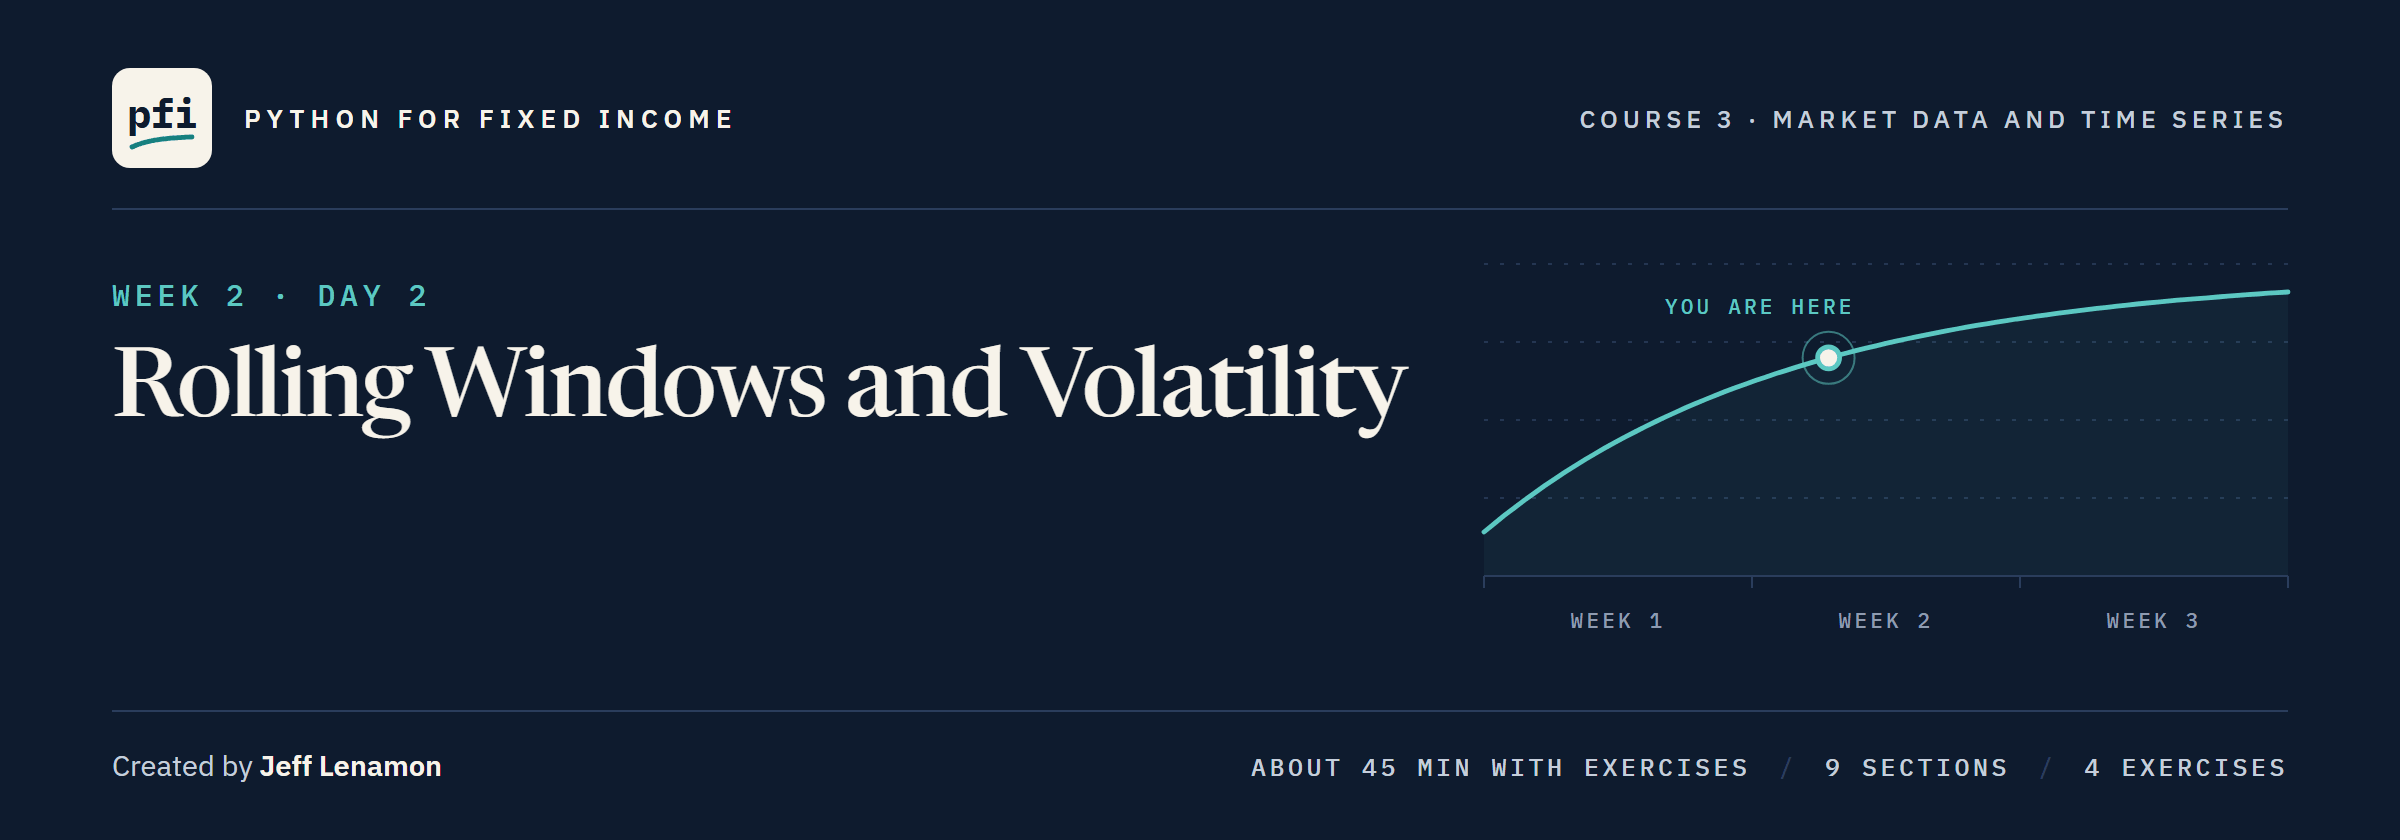

# Rolling Windows and Volatility

Week 2, Day 2. How much a series has been moving: the sample standard deviation of daily changes in bp over a trailing window of rows, per day or labelled per year, tied to Excel and tested for lookahead.

> This course is educational content created in a personal capacity. Nothing here is investment advice or a recommendation to buy or sell any security. All portfolio data is synthetic.

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/lenamonj/python-fixed-income/blob/main/course03_market_data/week2/day2/07_rolling_windows_and_volatility.ipynb)

### The Desk Lead's Note

> Two of our screens show the 10-year's volatility as 5.29 and 84.05 bp, from the same Treasury file, and neither says what it is. Give `marketdata` one definition: a window in rows, trailing, full windows only, the sample standard deviation of daily changes in bp, per day unless the name says annual. Tie it to Excel's `STDEV.S` filled down, prove no future row ever reaches today's number, and show me the 10-year over about one, three and twelve months as of 2 October. Describe how much it moved, with no view on what comes next.

The lesson reads only the Treasury file, and the exercises the synthetic spreads, invented for this course.
There is no key cell and no live cell today.

**Notebook 06 measured each day's move; today measures how much those moves vary.**

### Today's Work Folder

Q. Where does today's work happen?

In [1]:
import os
import sys

# start_day.py sets up each day. On your machine Python finds it in the repo's start_of_day folder;
# in Colab there is no repo, so the cell downloads it from the course's GitHub page.
github = 'https://raw.githubusercontent.com/lenamonj/python-fixed-income/main/'
if os.path.exists('../../start_of_day/start_day.py'):
    sys.path.insert(0, '../../start_of_day')
else:
    !wget -q {github}course03_market_data/start_of_day/start_day.py
from start_day import start_day

# a new work folder: the data files, Course 2's bondmath.py, and marketdata.py, its tests,
# and their Git history as notebook 06 left them.
# To start the day again, restart the kernel and run all cells.
work = start_day(7)

Work folder pfi_course3_07_k4w7q2xr: 4 data files, Course 2's bondmath.py, marketdata.py as notebook 06 left it, 6 commits, tagged week1


### The Tests Pass Before We Start

In [2]:
import subprocess
import sys

# python -m pytest -q on the test file, with this notebook's own Python and no cache folder
command = [sys.executable, '-m', 'pytest', '-q', '-p', 'no:cacheprovider', 'test_marketdata.py']
# run it in the work folder and keep what it prints
result = subprocess.run(command, cwd=work, capture_output=True, text=True)
print(result.stdout + result.stderr)

.........................                                                [100%]
25 passed in 0.50s



### Imports and the 10 Yr's Changes

In [3]:
import importlib
import math

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

import marketdata as md

# the house greens and greys, as in Course 1's Visualization notebook
sns.set_theme(style='whitegrid', palette=['#2E7D5B', '#9AA5B1', '#1E4D3A', '#52606D'])

In [4]:
# the Treasury file, yields in percent, every digit as written
treasury = pd.read_csv('treasury_par_yields.csv', parse_dates=['date'], index_col='date',
                       float_precision='round_trip')
ten = treasury['10 Yr']
# notebook 06's daily changes in bp, the first (NaN) dropped
ten_changes = md.change_bp(ten).dropna()
print(f'{len(ten):,} levels, {len(ten_changes):,} daily changes in bp')

2,940 levels, 2,939 daily changes in bp


**Every window today runs over these 2,939 daily changes of the 10 Yr, in bp.**

## Your Route Through Day 2

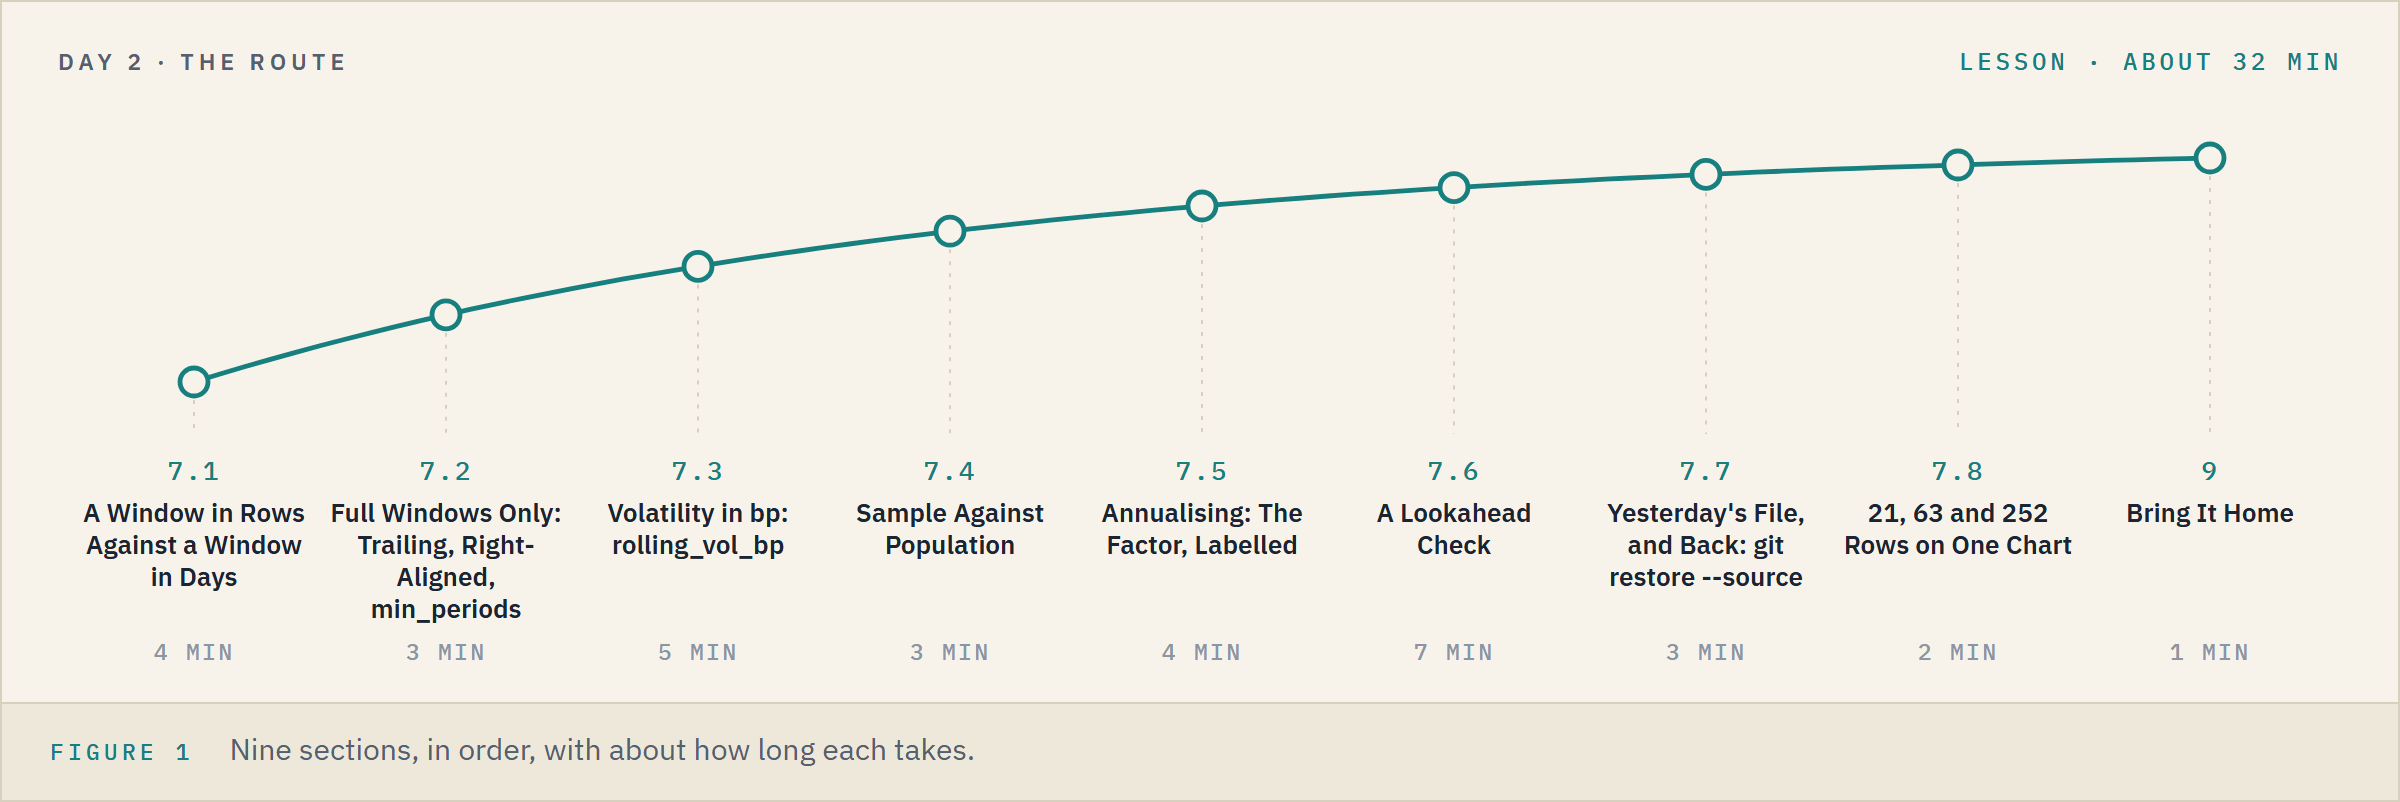

**Time.** About 32 minutes for the lesson, then about 12 for the four exercises.

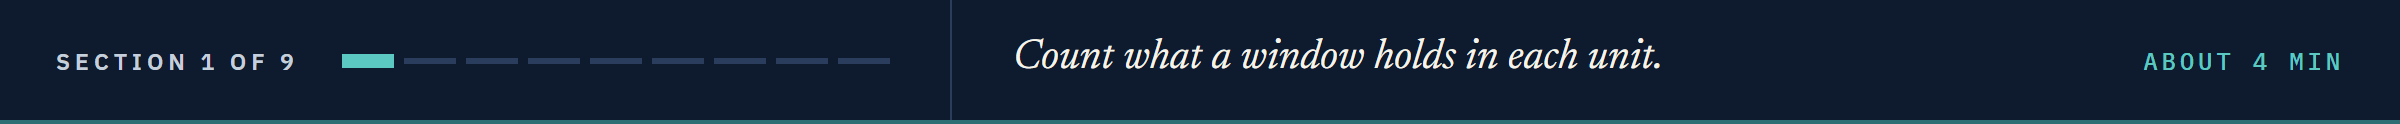

## 7.1 A Window in Rows Against a Window in Days

The note's first choice is what a window holds.
Course 1's Treasury Yields case study used `rolling(20)`, the last 20 rows, its picture "A 20-Row Window".
`rolling('7D')` takes every row dated in the last 7 calendar days instead.
`.count()` after `.rolling()` counts the values in each window.

### Predict 1: A Seven-Day Window

**Predict 1**

Q. Over the 10 Yr's changes, how many rows does each `rolling('7D')` window hold?

A) 5 on every date: a week has five market days
B) 4 or 5
C) anything from 2 to 7

### Count the Rows in Each

In [5]:
# the rows dated in the 7 calendar days ending on each date
days_7 = ten_changes.rolling('7D').count()
# from February 2015, once every window lies inside the file; how often each count
days_7.loc['2015-02':].value_counts()

10 Yr
5.0    2420
4.0     500
Name: count, dtype: int64

B.

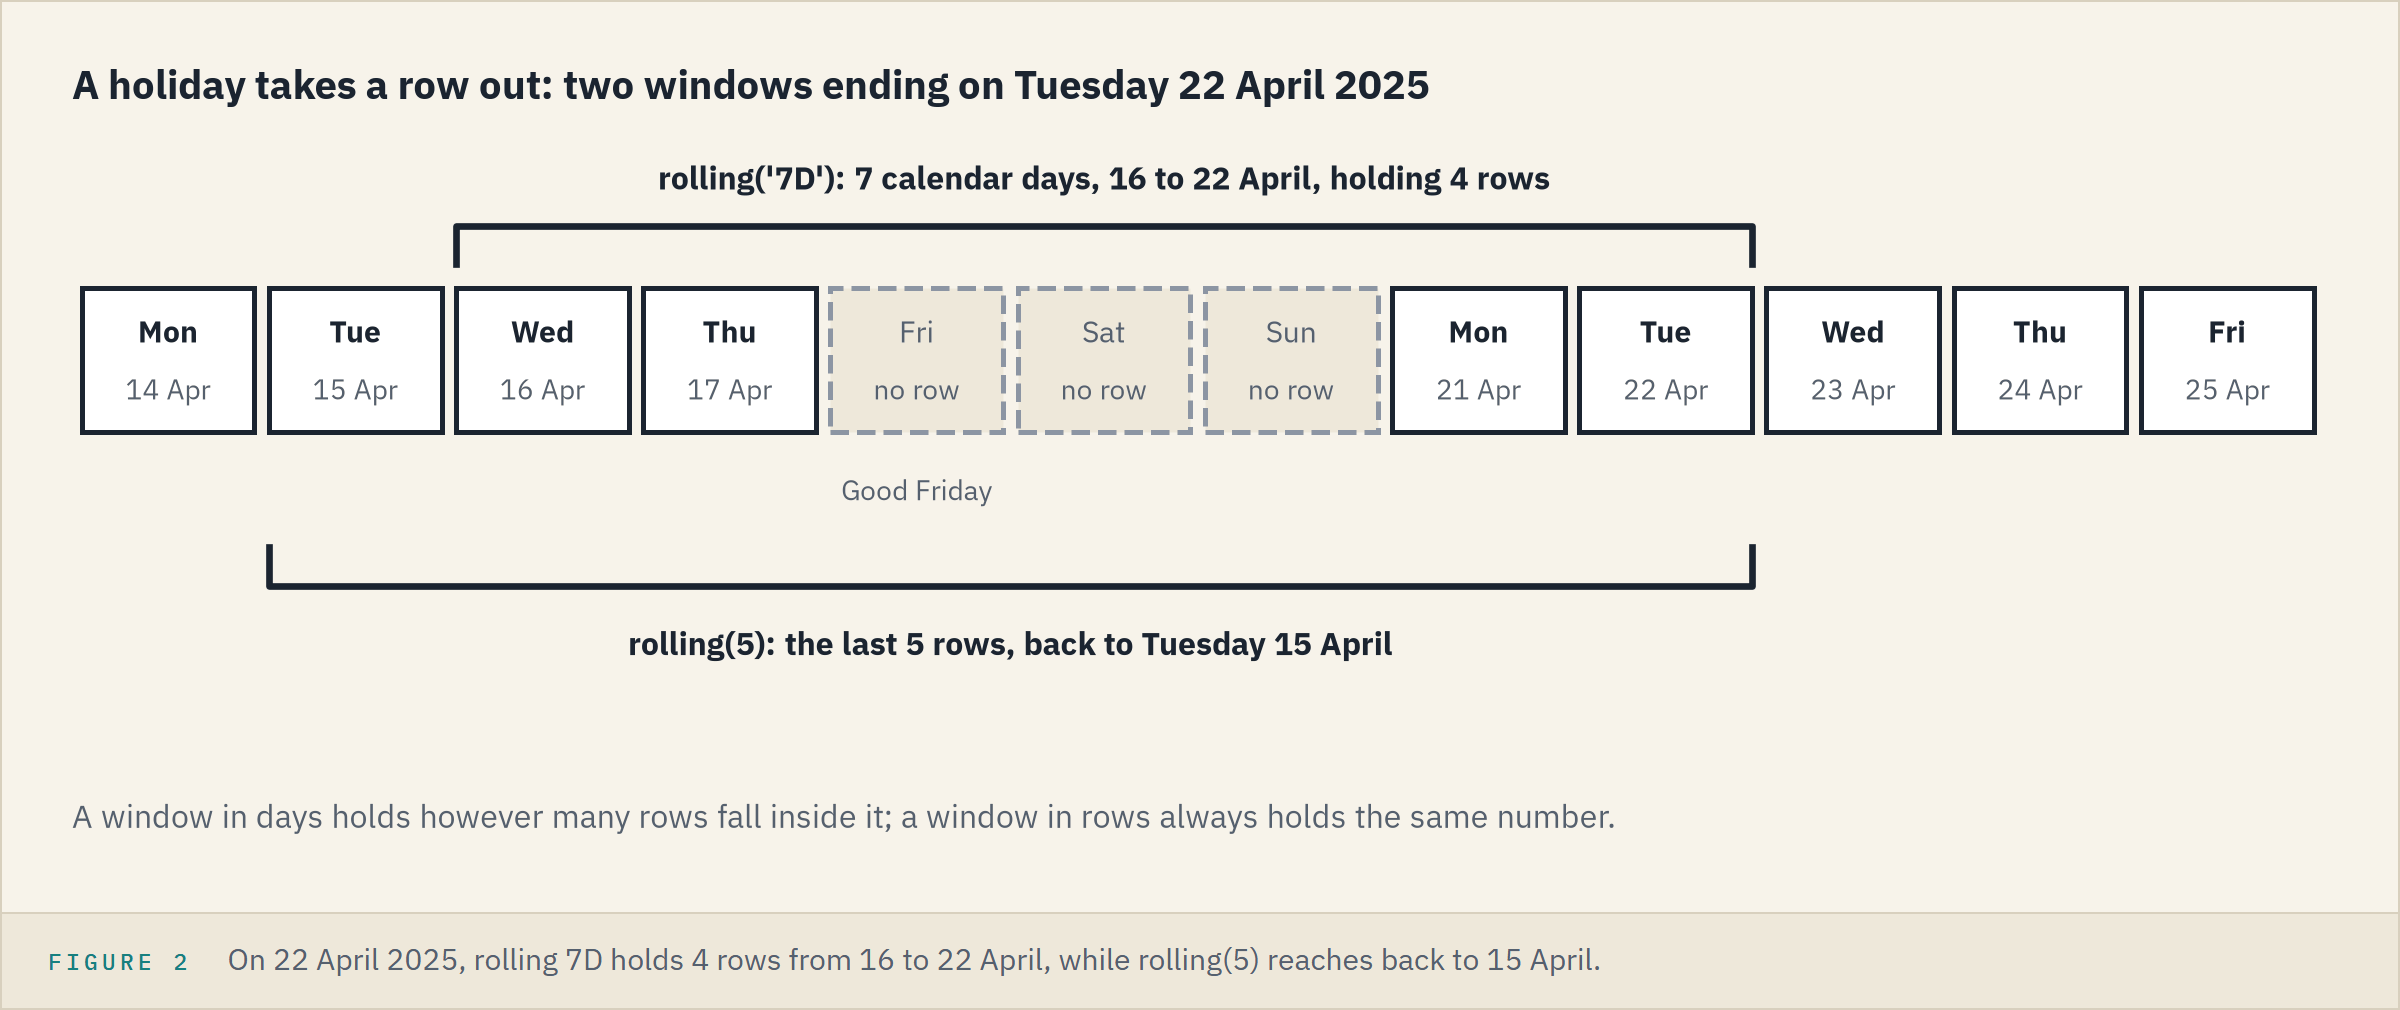

A holiday takes a row out of a calendar window.

### Thirty Days, Every Date

In [6]:
# rows in each 30-day window, how many dates hold each count, and the share holding 21
days_30 = ten_changes.rolling('30D').count()
counts = days_30.loc['2015-02':].value_counts().sort_index()
share = counts[21] / counts.sum() * 100

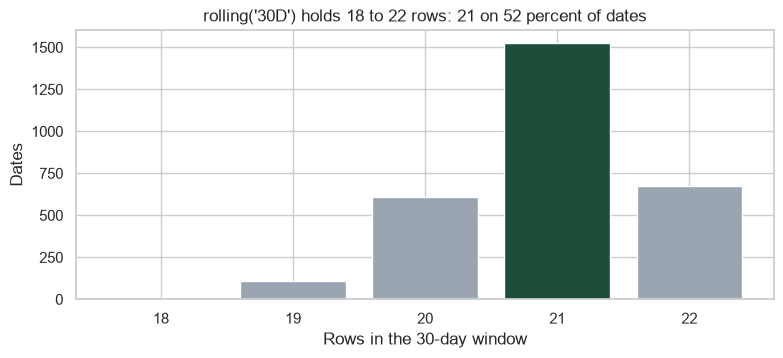

In [7]:
# one bar per count of rows
fig, ax = plt.subplots(figsize=(9, 3.5))
ax.bar(counts.index, counts.values, color='#9AA5B1')
# 21 rows drawn again on top, in the dark green
ax.bar(21, counts[21], color='#1E4D3A')
ax.set_title(f"rolling('30D') holds 18 to 22 rows: 21 on {share:.0f} percent of dates")
ax.set_xlabel('Rows in the 30-day window')
ax.set_ylabel('Dates')
plt.show()

`rolling(21)` holds 21 on every date.

**Excel side by side.** Dates in A, the 10 Yr's changes from row 3.

<table align="left">
<tr><th align="left">Job</th><th align="left">Python</th><th align="left">Excel</th><th align="left">Result</th></tr>
<tr><td align="left">Rows in the last 30 calendar days, filled down</td><td align="left"><code>ten_changes.rolling('30D').count()</code></td><td align="left"><code>=COUNTIFS($A$3:$A$2941,"&gt;"&amp;A3-30,$A$3:$A$2941,"&lt;="&amp;A3)</code></td><td align="left">Equal on all 2,939 rows, 21 on the last</td></tr>
</table>
<br clear="left">

### The First Date

In [8]:
# the first three dates: a 30-day mean and a 21-row mean
first = pd.DataFrame({"rolling('30D')": ten_changes.rolling('30D').mean(),
                      'rolling(21)': ten_changes.rolling(21).mean()})
first.head(3).round(2)

,rolling('30D'),rolling(21)
date,,
2015-01-05,-8.00,NaN
2015-01-06,-7.50,NaN
2015-01-07,-5.33,NaN


The 30-day window gives a mean of one change on the first date; the 21-row window waits.
pandas waits for a full window of rows, but gives a time window a number from its first row.

**A window in rows always holds the same number of changes, a window in days does not. The course counts rows: 21, 63 and 252, "about one month, three months, one year", conventions rather than calendar months.**

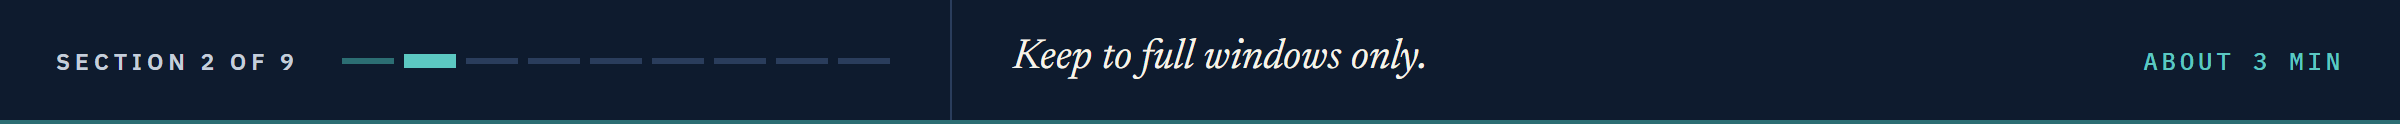

## 7.2 Full Windows Only: Trailing, Right-Aligned, `min_periods`

The 21-row window waited for 21 rows.
**Trailing** means the window ending on t holds t and the rows before it.
**Right-aligned** means pandas stores that window's value on t, as Course 1's picture showed.
`min_periods` is how many values a window needs before it gives a number.

### Six Changes, Two Rules

In [9]:
# six made-up daily changes in bp, then a 3-row mean two ways
hand = pd.Series([1.0, 3.0, 2.0, 5.0, 4.0, 6.0])
means = pd.DataFrame({'change': hand,
                      'full windows': hand.rolling(3, min_periods=3).mean(),
                      'min_periods=1': hand.rolling(3, min_periods=1).mean()})
means.round(2)

,change,full windows,min_periods=1
0,1.0,NaN,1.00
1,3.0,NaN,2.00
2,2.0,2.00,2.00
3,5.0,3.33,3.33
4,4.0,3.67,3.67
5,6.0,5.00,5.00


By hand, the first full window is (1 + 3 + 2) / 3 = 2.
The first two `min_periods=1` values are means of one and two changes, a different statistic under the same name.

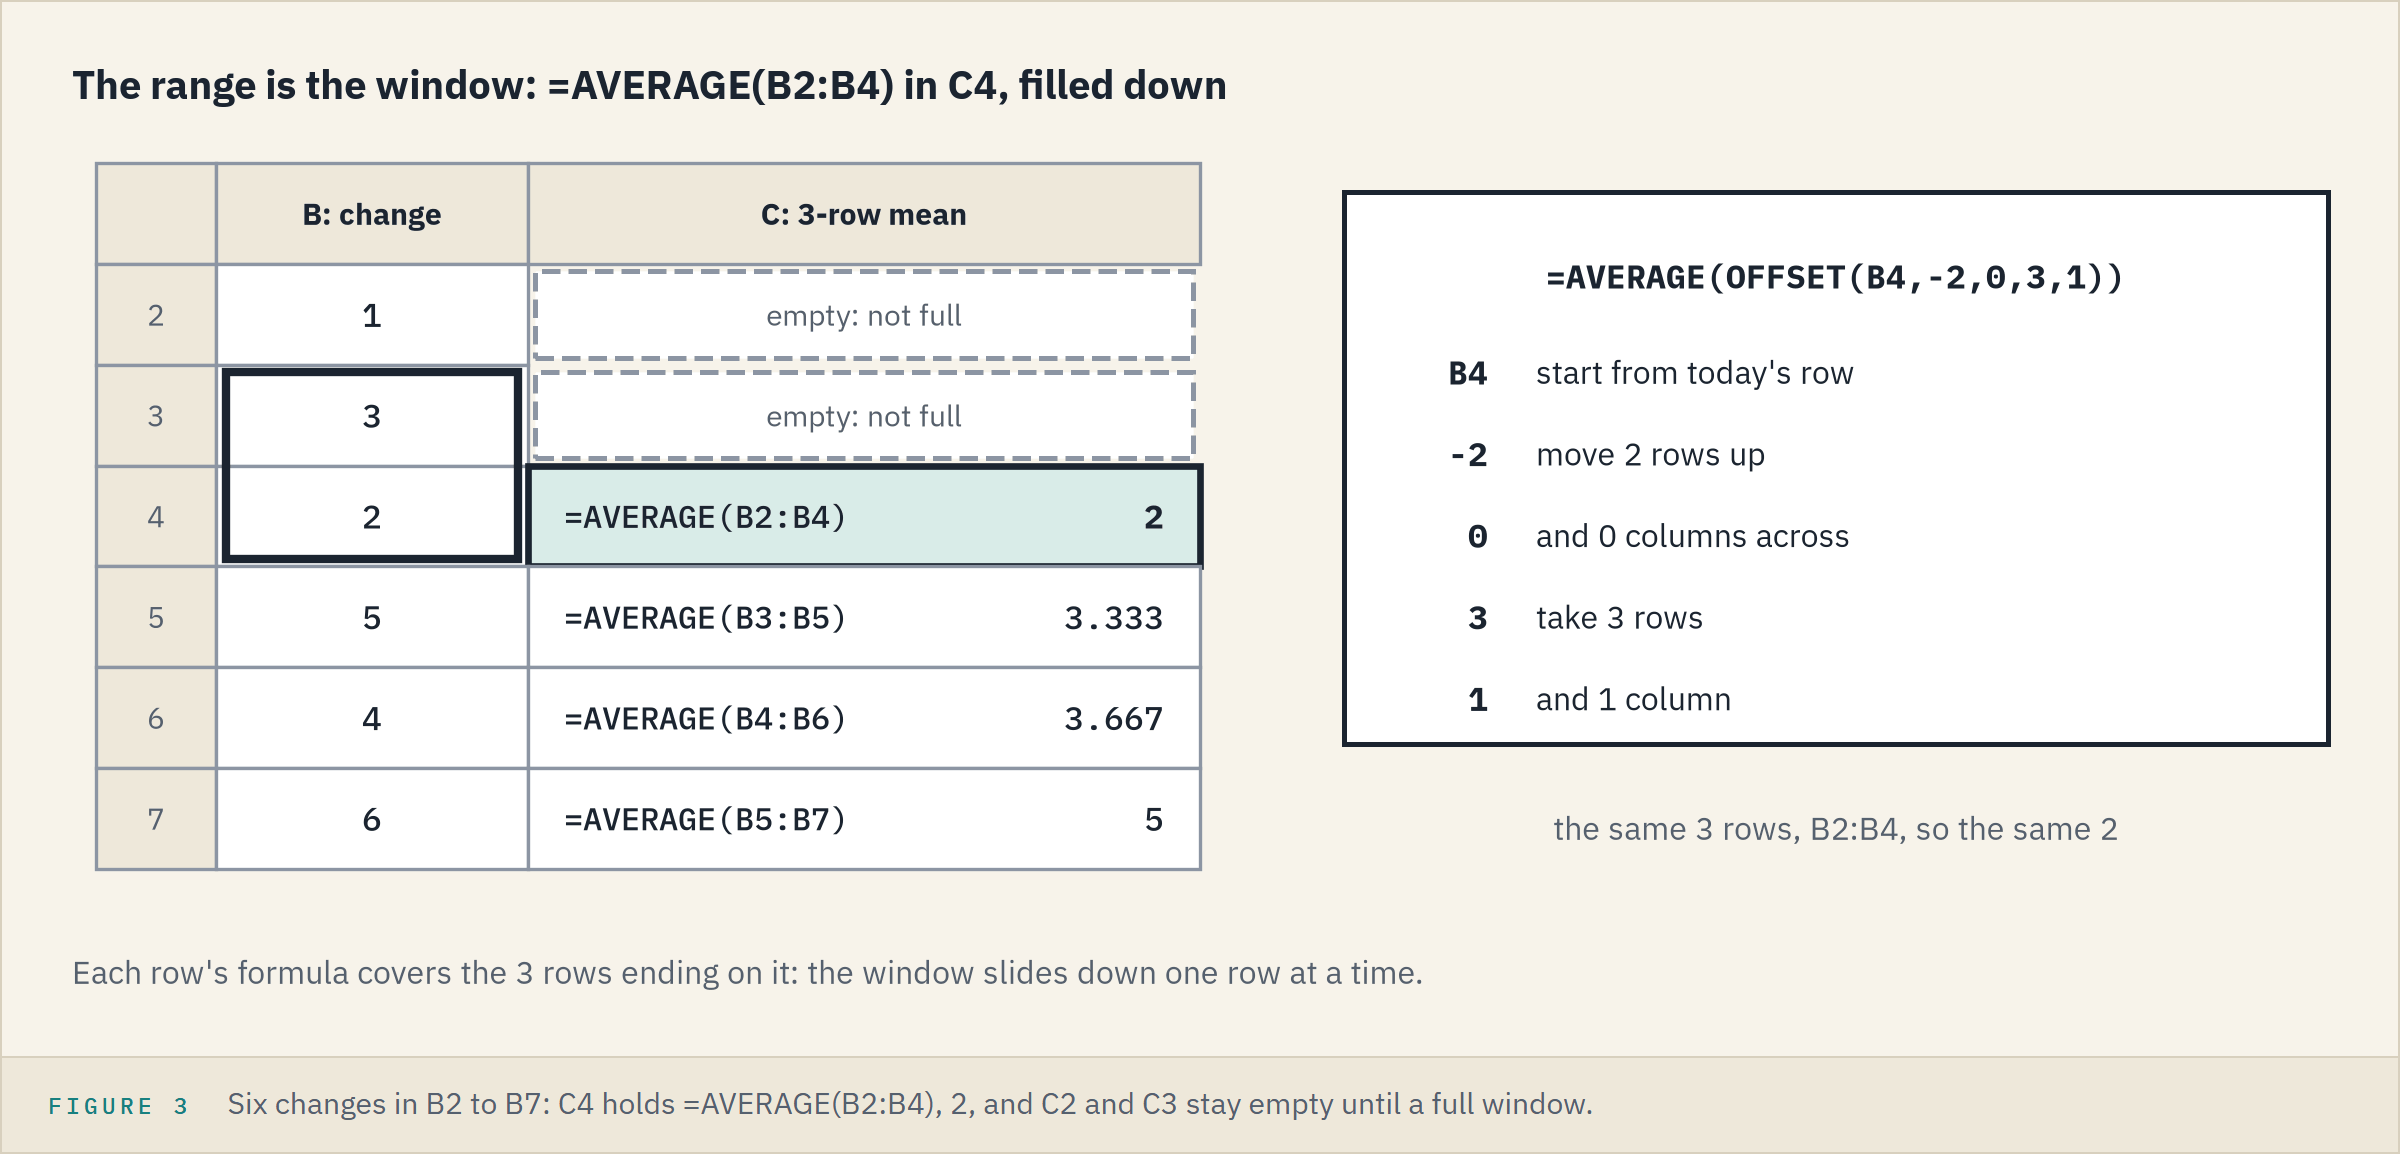

**Excel side by side.** The six changes in B2:B7.

<table align="left">
<tr><th align="left">Job</th><th align="left">Python</th><th align="left">Excel</th><th align="left">Result</th></tr>
<tr><td align="left">3-row mean, C4 filled down</td><td align="left"><code>hand.rolling(3, min_periods=3).mean()</code></td><td align="left"><code>=AVERAGE(B2:B4)</code></td><td align="left">2, 3.333, 3.667, 5, with C2 and C3 empty</td></tr>
<tr><td align="left">The same window by offset</td><td align="left">the same</td><td align="left"><code>=AVERAGE(OFFSET(B4,-2,0,3,1))</code></td><td align="left">2, 3.333, 3.667, 5</td></tr>
<tr><td align="left">A growing range, the changes in A1 to A3</td><td align="left"><code>min_periods=1</code></td><td align="left"><code>=AVERAGE(A$1:A1)</code> filled down</td><td align="left">1, 2, 2</td></tr>
</table>
<br clear="left">

### 63 Rows of the 10 Yr Against Excel

In [10]:
# Excel's answers: one row per 2026 market date, every value computed by Excel
reference = pd.read_csv('course3_excel_reference.csv', parse_dates=['date'], index_col='date',
                        float_precision='round_trip')
mean63 = ten.rolling(63, min_periods=63).mean()
gap = (mean63.loc[reference.index] - reference['mean63_10y_pct']).abs().max()
print(f'{len(reference)} rows of 2026, largest gap {gap:.1e} percent')

190 rows of 2026, largest gap 1.8e-15 percent


**Excel side by side.** The whole file on one sheet: dates in A, the 2, 5, 10 and 30 Yr in B to E from row 2, and the 10 Yr's change `=(D3-D2)*100` in F3 filled down.

<table align="left">
<tr><th align="left">Job</th><th align="left">Python</th><th align="left">Excel</th><th align="left">Result</th></tr>
<tr><td align="left">63-row mean of the 10 Yr, L64 filled down</td><td align="left"><code>ten.rolling(63, min_periods=63).mean()</code></td><td align="left"><code>=AVERAGE(D2:D64)</code></td><td align="left">Within 2.7e-15 percent on every row</td></tr>
<tr><td align="left">The same by offset, M64</td><td align="left">the same</td><td align="left"><code>=AVERAGE(OFFSET(D64,-62,0,63,1))</code></td><td align="left">Within 2.7e-15 percent on every row</td></tr>
</table>
<br clear="left">

**Full windows only: `min_periods` equals the window, so the first window - 1 values are NaN, as Excel leaves the cells above the first full range empty.**

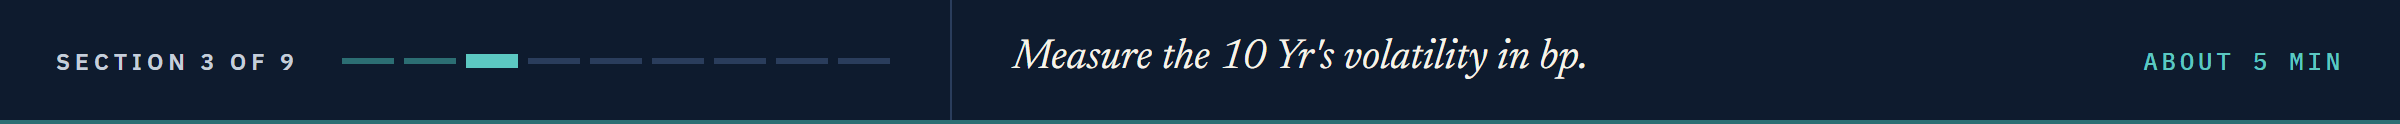

## 7.3 Volatility in bp: `rolling_vol_bp`

Now the statistic itself, over the changes and never the levels.
Changes go in, in bp, and the result comes out in bp per day.
The window counts rows, with `min_periods` equal to it, and the standard deviation is the sample one, `ddof=1`, Excel's `STDEV.S`.
`annualise` is 7.5's subject.
It refuses a window below 2 and, through notebook 04's `_check_series`, a missing value or a bad index.

### Append It, Docstring First

In [11]:
%%writefile -a marketdata.py


import math  # the annualising factor, from day 7

# the course's annualising convention for daily figures; other desks use other factors
TRADING_DAYS_PER_YEAR = 252


def rolling_vol_bp(changes_bp: pd.Series, window: int = 63, annualise: bool = False) -> pd.Series:
    """Rolling volatility of daily changes in bp: the sample standard deviation over a trailing window.

    Units: changes in bp in, bp out (per day; per year when annualise=True).
    Convention: the window ending on date t holds t and the window - 1 rows before it (rows, not calendar
    days); min_periods = window, so the first window - 1 values are NaN; sample standard deviation (ddof=1,
    Excel STDEV.S). annualise=True multiplies by sqrt(252), a convention.
    Excel: =STDEV.S(F2:F64) filled down, and =STDEV.S(F2:F64)*SQRT(252)
    Raises ValueError if window is below 2, the changes have missing values (the first change is NaN, so pass
    change_bp(...).dropna()), or the index is not unique ascending dates.
    """
    _check_series(changes_bp, "changes_bp")
    if window < 2:
        raise ValueError(f"window must be at least 2 rows, not {window}")
    # trailing window of `window` rows, full windows only, sample standard deviation
    vol = changes_bp.rolling(window, min_periods=window).std(ddof=1)
    # per year only when asked for
    if annualise:
        vol = vol * math.sqrt(TRADING_DAYS_PER_YEAR)
    return vol

Appending to marketdata.py


`math.sqrt` is the square root, as Course 1's `np.sqrt`.

### The Note's 5.29

In [12]:
importlib.reload(md)
# the 10 Yr's 21-row volatility, in bp per day
vol21 = md.rolling_vol_bp(ten_changes, window=21)
# :%Y-%m-%d writes the date, as in notebook 06
print(f'{vol21.isna().sum()} NaN, the first value on {vol21.dropna().index[0]:%Y-%m-%d}')
print(f'2026-10-02: {vol21.iloc[-1]:.2f} bp a day')

20 NaN, the first value on 2015-02-03
2026-10-02: 5.29 bp a day


The note's first number, with a definition behind it.

### 2026, Drawn

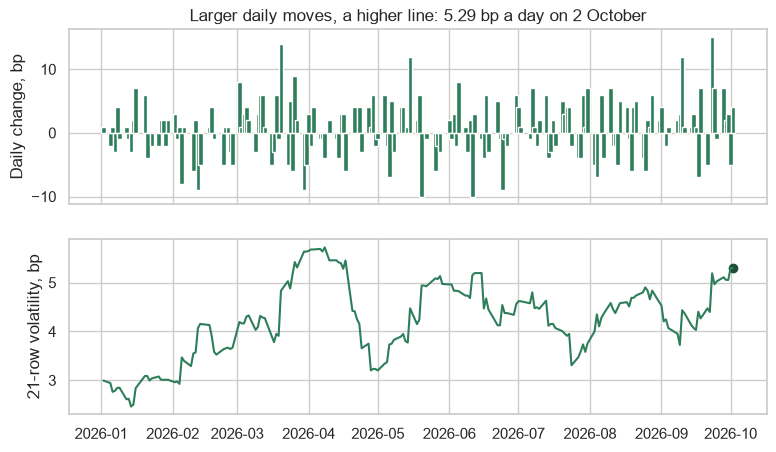

In [13]:
# 2026's daily changes above, their 21-row volatility below, on one date axis
fig, (top, bottom) = plt.subplots(2, 1, figsize=(9, 5), sharex=True)
top.bar(ten_changes.loc['2026'].index, ten_changes.loc['2026'], width=2)
top.set_ylabel('Daily change, bp')
top.set_title('Larger daily moves, a higher line: 5.29 bp a day on 2 October')
bottom.plot(vol21.loc['2026'])
bottom.scatter(vol21.index[-1], vol21.iloc[-1], color='#1E4D3A')
bottom.set_ylabel('21-row volatility, bp')
plt.show()

### Every 2026 Row Against `STDEV.S`

In [14]:
# the 21-row volatility against Excel's, and the formula Excel ran on 2 January
gap = (vol21.loc[reference.index] - reference['vol21_10y_bp']).abs().max()
print(f'{len(reference)} rows of 2026, largest gap {gap:.1e} bp')
print(reference['vol21_10y_bp_formula'].iloc[0])

190 rows of 2026, largest gap 2.4e-14 bp
=STDEV.S(F242:F262)


Python and Excel differ only in the last binary digits, far inside the course's 1e-9 bp.
The reference sheet starts in December 2024, so its row numbers differ from the whole-file sheet below.

**Excel side by side.** The whole-file sheet of 7.2.

<table align="left">
<tr><th align="left">Job</th><th align="left">Python</th><th align="left">Excel</th><th align="left">Result</th></tr>
<tr><td align="left">21-row volatility, G23 filled down</td><td align="left"><code>md.rolling_vol_bp(ten_changes, window=21)</code></td><td align="left"><code>=STDEV.S(F3:F23)</code></td><td align="left">Within 2.4e-14 bp on all 2,919 rows, the last 5.294651389216601</td></tr>
<tr><td align="left">The same by offset, N23</td><td align="left">the same</td><td align="left"><code>=STDEV.S(OFFSET(F23,-20,0,21,1))</code></td><td align="left">Within 2.4e-14 bp</td></tr>
</table>
<br clear="left">

### Two Tests

In [15]:
%%writefile -a test_marketdata.py


def ten_year_changes() -> pd.Series:
    """Daily changes of the 10 Yr in bp, the first (NaN) dropped."""
    return md.change_bp(read_treasury()["10 Yr"]).dropna()


def test_vol_matches_excel_reference():
    reference = read_reference()
    vol = md.rolling_vol_bp(ten_year_changes(), window=21)
    vol_annual = md.rolling_vol_bp(ten_year_changes(), window=21, annualise=True)
    for day, row in reference.iterrows():
        # Excel: =STDEV.S(F242:F262) filled down, and =G262*SQRT(252)
        assert vol.loc[day] == pytest.approx(row["vol21_10y_bp"], abs=1e-9), day
        assert vol_annual.loc[day] == pytest.approx(row["vol21_10y_annual_bp"], abs=1e-8), day


def test_vol_min_periods_nan():
    vol = md.rolling_vol_bp(ten_year_changes(), window=21)
    # no partial windows: 20 NaN, then values
    assert vol.iloc[:20].isna().all()
    assert vol.iloc[20:].notna().all()

Appending to test_marketdata.py


The Excel test also checks the annual column, which 7.5 explains.

### Run pytest

In [16]:
import subprocess
import sys

# python -m pytest -q on the test file, with this notebook's own Python and no cache folder
command = [sys.executable, '-m', 'pytest', '-q', '-p', 'no:cacheprovider', 'test_marketdata.py']
# run it in the work folder and keep what it prints
result = subprocess.run(command, cwd=work, capture_output=True, text=True)
print(result.stdout + result.stderr)

...........................                                              [100%]
27 passed in 0.50s



### Forget `.dropna()`

In [17]:
# the changes as change_bp returns them, the first one NaN
md.rolling_vol_bp(md.change_bp(ten), window=21)

ValueError: changes_bp has 1 missing values; drop them first with .dropna()

**`rolling_vol_bp` is Excel's `STDEV.S` filled down, on every row of 2026: 5.29 bp a day for the 10 Yr on 2 October.**

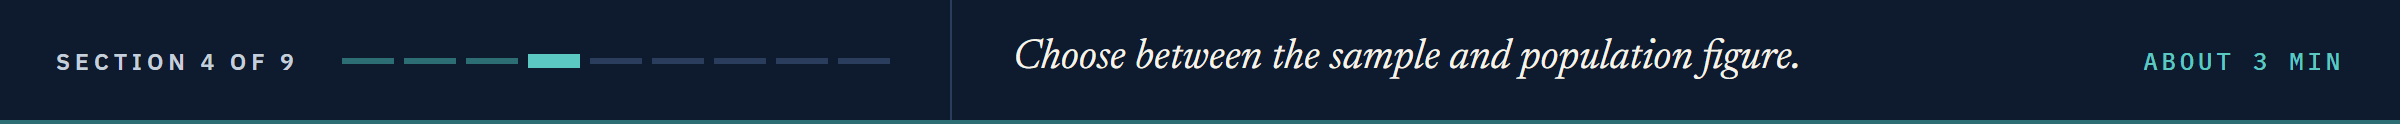

## 7.4 Sample Against Population

Excel has two standard deviations.
The sample one divides by n - 1 and the population one by n, as in Course 1's NumPy Part 1.
A window is a sample of the series, so the course uses the sample one.

<table align="left">
<tr><th align="left"></th><th align="left">Divides by</th><th align="left">pandas</th><th align="left">NumPy</th><th align="left">Excel</th></tr>
<tr><td align="left">Sample</td><td align="left">n - 1</td><td align="left"><code>.std()</code>, <code>ddof=1</code> the default</td><td align="left"><code>np.std(x, ddof=1)</code></td><td align="left"><code>STDEV.S</code></td></tr>
<tr><td align="left">Population</td><td align="left">n</td><td align="left"><code>.std(ddof=0)</code></td><td align="left"><code>np.std(x)</code>, <code>ddof=0</code> the default</td><td align="left"><code>STDEV.P</code></td></tr>
</table>
<br clear="left">

### The Last 21 Changes, Both Ways

In [18]:
# the last 21 daily changes, in bp
last_21 = ten_changes.iloc[-21:]
sample, population = last_21.std(ddof=1), last_21.std(ddof=0)
print(f'sample {sample:.6f}, population {population:.6f}, '
      f'np.std {np.std(last_21.to_numpy()):.6f} bp')
print(f'sample / population: {sample / population:.6f}')

sample 5.294651, population 5.167051, np.std 5.167051 bp
sample / population: 1.024695


**Excel side by side.**

<table align="left">
<tr><th align="left">Job</th><th align="left">Python</th><th align="left">Excel</th><th align="left">Result</th></tr>
<tr><td align="left">Population volatility, H23 filled down</td><td align="left"><code>.rolling(21).std(ddof=0)</code></td><td align="left"><code>=STDEV.P(F3:F23)</code></td><td align="left">Within 2.4e-14 bp, the last 5.167050676973533</td></tr>
<tr><td align="left">One value</td><td align="left">a window of 1</td><td align="left"><code>=STDEV.S(A1)</code></td><td align="left"><code>#DIV/0!</code>, which is why the window is at least 2</td></tr>
</table>
<br clear="left">

### Predict 2: At 252 Rows

**Predict 2**

Q. At 21 rows the sample figure is 1.024695 times the population one. At 252 rows the gap is:

A) about the same, 2.5 percent
B) about 0.2 percent
C) about 25 percent

### Both Ratios

In [19]:
# sample over population for the last 21 and the last 252 changes
for n in [21, 252]:
    changes_n = ten_changes.iloc[-n:]
    print(f'{n} rows: {changes_n.std(ddof=1) / changes_n.std(ddof=0):.6f}, '
          f'sqrt(n / (n - 1)) = {math.sqrt(n / (n - 1)):.6f}')

21 rows: 1.024695, sqrt(n / (n - 1)) = 1.024695
252 rows: 1.001990, sqrt(n / (n - 1)) = 1.001990


B: the ratio is the square root of n / (n - 1), whatever the data.

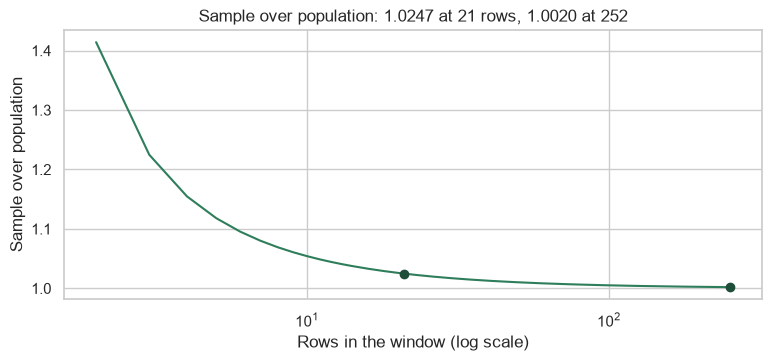

In [20]:
# the same ratio for every window from 2 to 252 rows
lengths = range(2, 253)
ratios = pd.Series([math.sqrt(n / (n - 1)) for n in lengths], index=lengths)
fig, ax = plt.subplots(figsize=(9, 3.5))
ax.plot(ratios.index, ratios)
ax.scatter([21, 252], ratios.loc[[21, 252]], color='#1E4D3A', zorder=3)
ax.set_xscale('log')
ax.set_title('Sample over population: 1.0247 at 21 rows, 1.0020 at 252')
ax.set_xlabel('Rows in the window (log scale)')
ax.set_ylabel('Sample over population')
plt.show()

**Excel side by side.** `=SQRT(21/20)` returns 1.024695.

**Sample is the course's choice, `ddof=1` and `STDEV.S`, while `np.std` with no `ddof` gives the other. The gap is 2.5 percent at 21 rows and 0.2 at 252, so name `ddof` whenever it matters.**

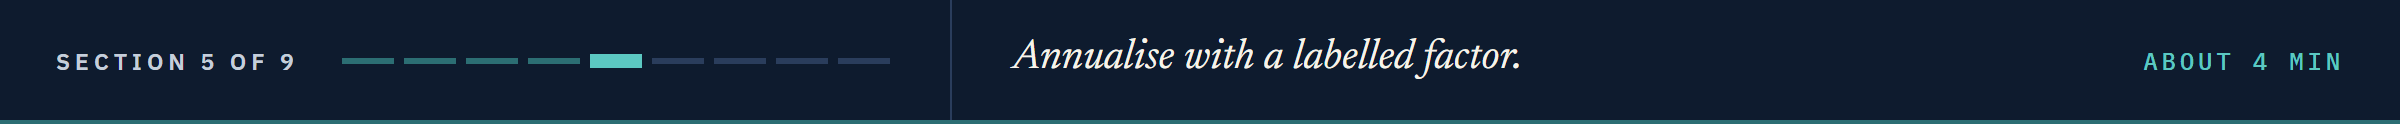

## 7.5 Annualising: The Factor, Labelled

Now the note's 84.05.
Per year is per day times the square root of 252.
Variances of independent days add, so the standard deviation grows with the square root of the number of days.
252 is a convention for the market days in a year, and other desks use others.

### Market Days per Year

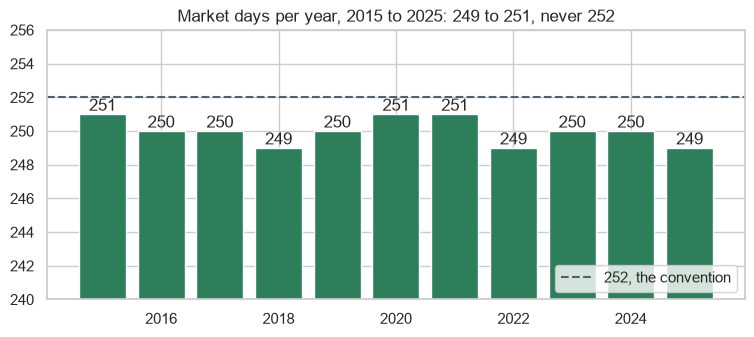

In [21]:
# rows per calendar year, 2015 to 2025 (2026 is not over)
rows_per_year = treasury.groupby(treasury.index.year).size().loc[:2025]
fig, ax = plt.subplots(figsize=(9, 3.5))
bars = ax.bar(rows_per_year.index, rows_per_year)
ax.bar_label(bars)
ax.axhline(252, color='#52606D', linestyle='--', label='252, the convention')
ax.set_ylim(240, 256)
ax.set_title('Market days per year, 2015 to 2025: 249 to 251, never 252')
ax.legend(loc='lower right')
plt.show()

**Excel side by side.**

<table align="left">
<tr><th align="left">Job</th><th align="left">Python</th><th align="left">Excel</th><th align="left">Result</th></tr>
<tr><td align="left">Rows in 2015</td><td align="left"><code>treasury.groupby(treasury.index.year).size()</code></td><td align="left"><code>=COUNTIFS($A$2:$A$2941,"&gt;="&amp;DATE(2015,1,1),$A$2:$A$2941,"&lt;"&amp;DATE(2016,1,1))</code></td><td align="left">251, and equal for all 11 years</td></tr>
</table>
<br clear="left">

### The Note's 84.05

In [22]:
# the same 21-row volatility, per year
vol21_annual = md.rolling_vol_bp(ten_changes, window=21, annualise=True)
print(f'{vol21_annual.iloc[-1]:.2f} bp a year = {vol21.iloc[-1]:.2f} x {math.sqrt(252):.4f}')
gap = (vol21_annual.loc[reference.index] - reference['vol21_10y_annual_bp']).abs().max()
print(f'largest gap from Excel over 2026: {gap:.1e} bp')

84.05 bp a year = 5.29 x 15.8745
largest gap from Excel over 2026: 3.8e-13 bp


The two screens show one measure in two units.

**Excel side by side.** `=G23*SQRT(252)` in I23, filled down, is within 3.8e-13 bp on every row, the last 84.04998512789868.

### Predict 3: A Desk That Uses 250

**Predict 3**

Q. Another desk annualises the same 5.29 bp a day with 250 days in place of 252. How many bp per year lower is its figure than 84.05? Write down a number.

### Both Factors

In [23]:
# the last 21-row volatility, per year by each factor
for days in [252, 250]:
    print(f'{days} days: {vol21.iloc[-1] * math.sqrt(days):.2f} bp a year')

252 days: 84.05 bp a year
250 days: 83.72 bp a year


0.33 bp a year: small, and still a second number for the same thing.

### The Factor, Tested

In [24]:
%%writefile -a test_marketdata.py


def test_vol_annualise_factor():
    changes = ten_year_changes()
    daily = md.rolling_vol_bp(changes, window=63)
    annual = md.rolling_vol_bp(changes, window=63, annualise=True)
    assert annual.iloc[-1] == pytest.approx(daily.iloc[-1] * math.sqrt(252), abs=1e-12)

Appending to test_marketdata.py


### Run pytest

In [25]:
import subprocess
import sys

# python -m pytest -q on the test file, with this notebook's own Python and no cache folder
command = [sys.executable, '-m', 'pytest', '-q', '-p', 'no:cacheprovider', 'test_marketdata.py']
# run it in the work folder and keep what it prints
result = subprocess.run(command, cwd=work, capture_output=True, text=True)
print(result.stdout + result.stderr)

............................                                             [100%]
28 passed in 0.50s



**84.05 is 5.29 times the square root of 252, one measure in two units. The factor is a convention, so it lives in the name (`_annual`) and the argument, never in silence.**

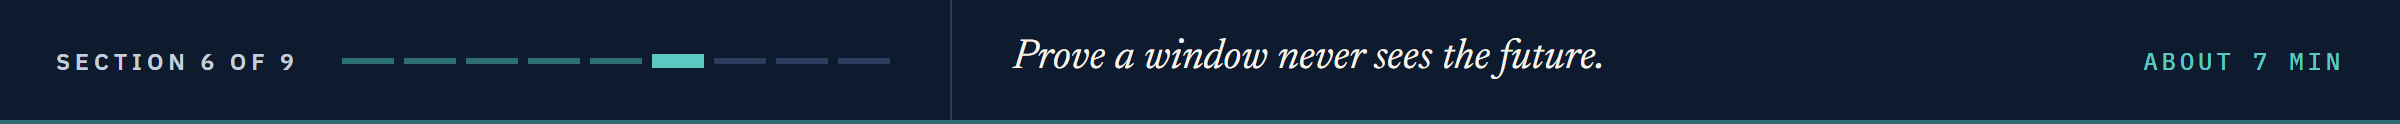

## 7.6 Lookahead: `assert_no_lookahead`

Every window so far ends on its own date.
**Lookahead** is a number for t built with rows after t.
On a screen it looks like any other number.
In a study of the past, it lets the past know the future.

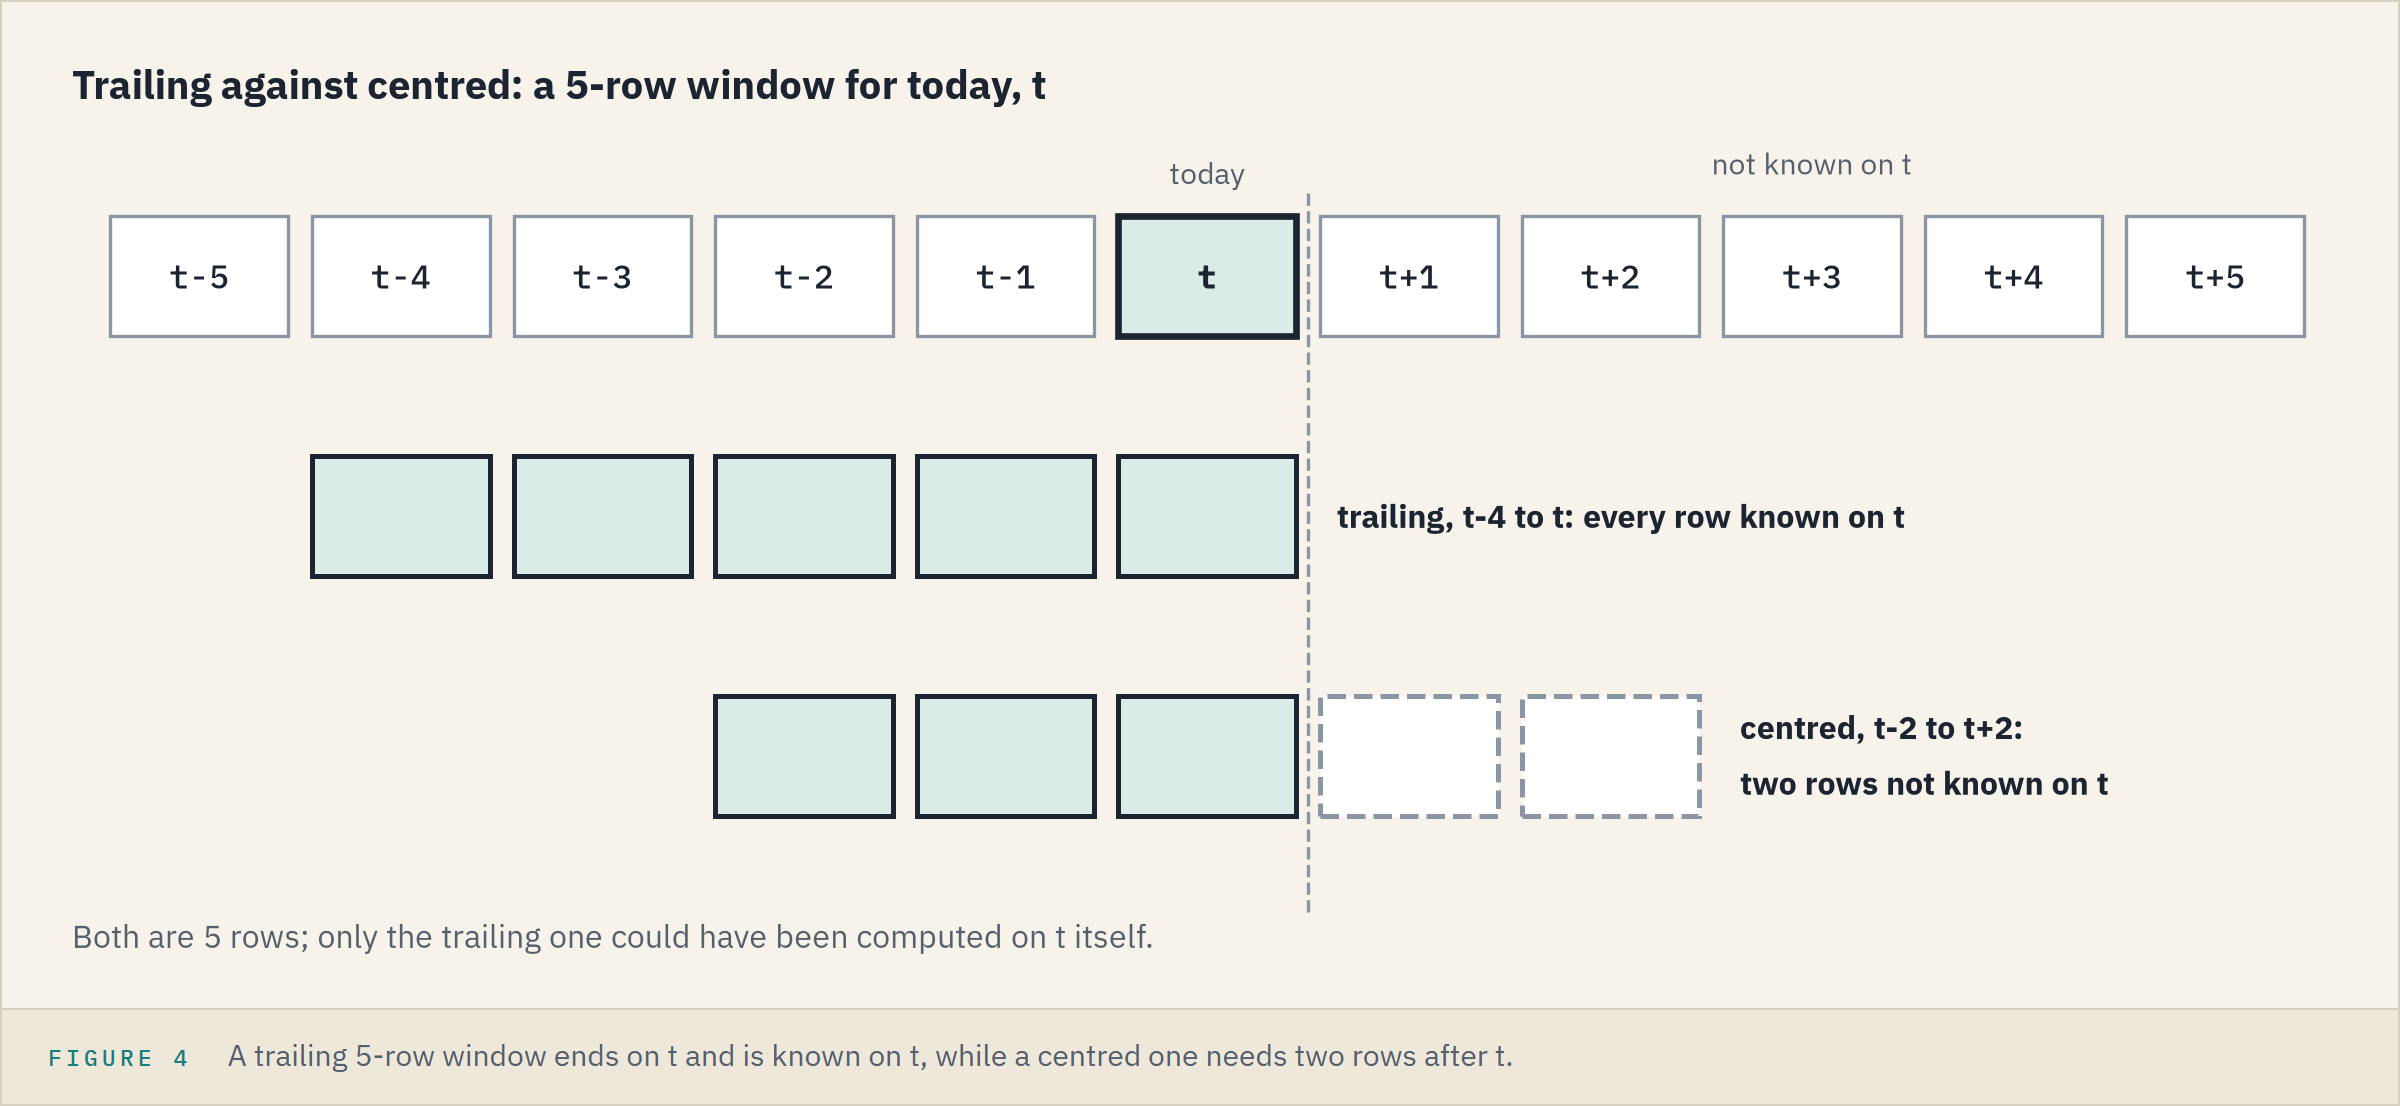

A **centred** window reaches past t.

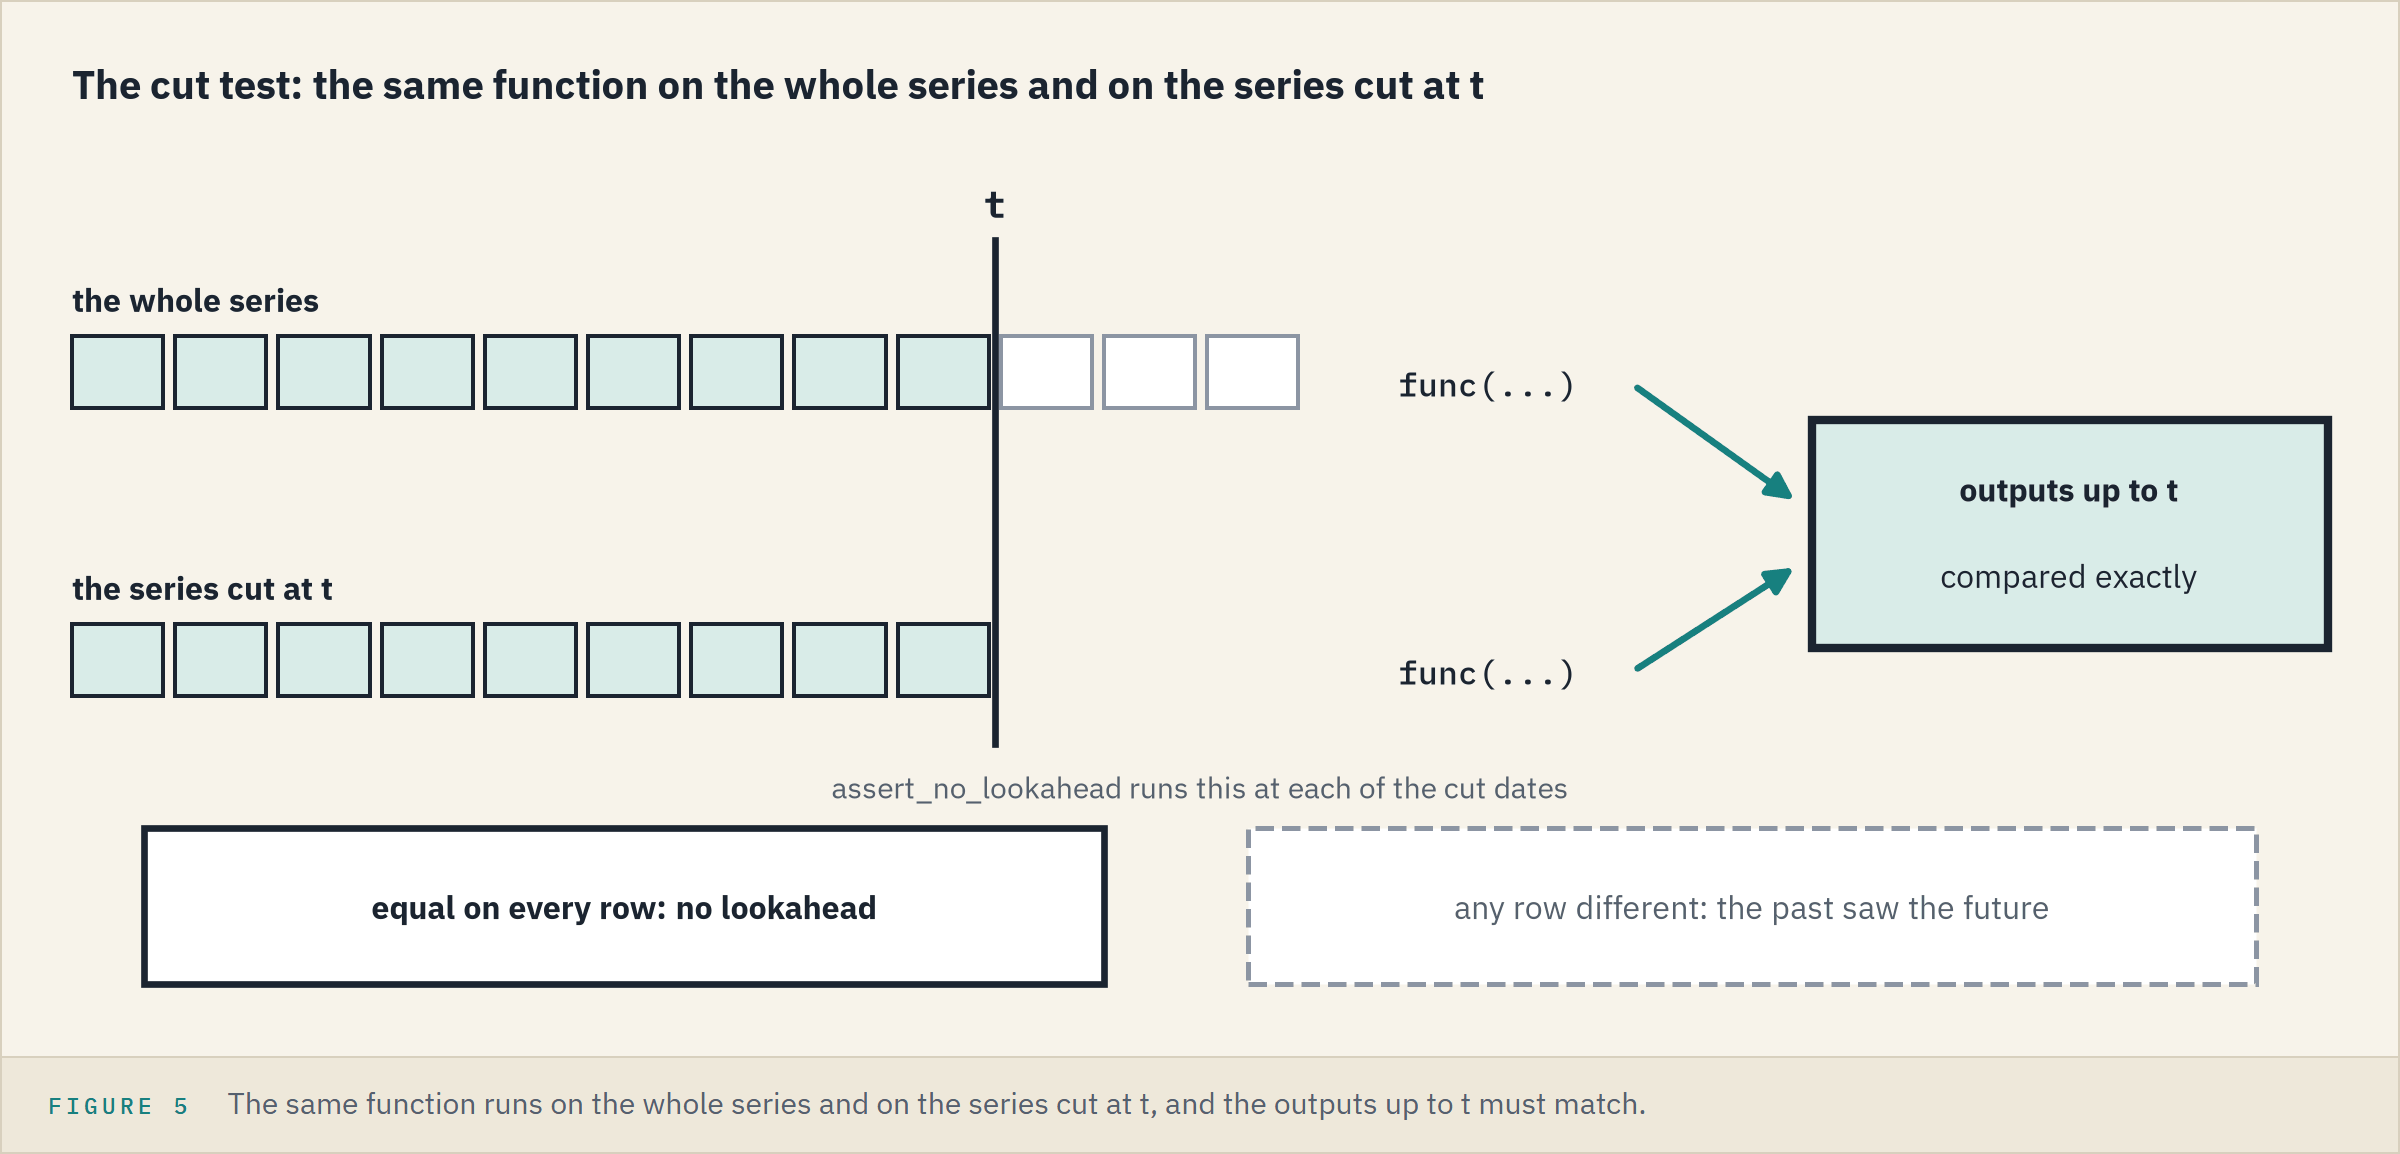

**The rule: a function's output up to t is the same whether the series stops at t or runs on, compared exactly.**

### The Helper and Its Test

In [26]:
%%writefile -a test_marketdata.py


def assert_no_lookahead(func, series, cut_dates):
    """Check that func uses no future data: its output up to each cut date is the same whether the series
    stops at that date or runs on past it (exact equality, no tolerance)."""
    full = func(series)
    for cut in cut_dates:
        cut = pd.Timestamp(cut)
        # the same function on the series cut at that date
        cut_result = func(series.loc[:cut])
        pd.testing.assert_series_equal(full.loc[:cut], cut_result, check_exact=True)


# dates to cut the series at in the no-lookahead tests: a holiday week, a month end, and the file's last week
CUT_DATES = ["2025-04-17", "2026-06-30", "2026-09-30"]


def test_vol_no_lookahead():
    assert_no_lookahead(lambda s: md.rolling_vol_bp(s, window=63), ten_year_changes(), CUT_DATES)

Appending to test_marketdata.py


`assert_series_equal(check_exact=True)` is notebook 05's, and `lambda` Course 1's one-line function.
The cut dates are the Thursday before Good Friday 2025, a month end, and the file's last week.

### Run pytest

In [27]:
import subprocess
import sys

# python -m pytest -q on the test file, with this notebook's own Python and no cache folder
command = [sys.executable, '-m', 'pytest', '-q', '-p', 'no:cacheprovider', 'test_marketdata.py']
# run it in the work folder and keep what it prints
result = subprocess.run(command, cwd=work, capture_output=True, text=True)
print(result.stdout + result.stderr)

.............................                                            [100%]
29 passed in 0.50s



### A Value Moved One Row Earlier

Q. A screen lines each day's volatility up with the next day's change. Does the check notice?

In [28]:
# the cut dates, imported from the test file as Course 2's Duration and DV01 imported its own
from test_marketdata import CUT_DATES


def vol_lined_up_with_next_day(changes):
    # shift(-1): each date takes the next row's value, notebook 03's .shift() the other way
    return md.rolling_vol_bp(changes, window=21).shift(-1)

In [29]:
# the helper's check written out, so the message names the date
full = vol_lined_up_with_next_day(ten_changes)
for cut in CUT_DATES:
    stopped = vol_lined_up_with_next_day(ten_changes.loc[:cut])
    assert full.loc[:cut].equals(stopped), f'values up to {cut} change when later rows arrive'

AssertionError: values up to 2025-04-17 change when later rows arrive

`.equals` is Course 1's: the same values on the same dates, every one.
It fails on the first cut date.

### April 2025, Both Lines

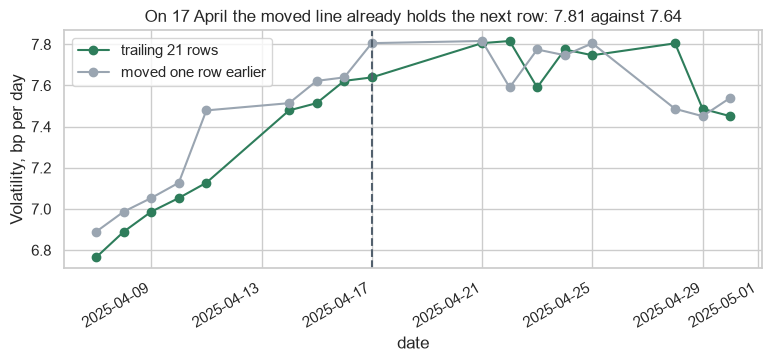

In [30]:
# the 21-row line and the same line moved one row earlier, around the first cut date
april = pd.DataFrame({'trailing 21 rows': vol21,
                      'moved one row earlier': vol21.shift(-1)}).loc['2025-04-07':'2025-04-30']
fig, ax = plt.subplots(figsize=(9, 3.5))
# marker='o': a dot on every row
april.plot(ax=ax, marker='o')
ax.axvline(pd.Timestamp('2025-04-17'), color='#52606D', linestyle='--')
ax.set_title('On 17 April the moved line already holds the next row: 7.81 against 7.64')
ax.set_ylabel('Volatility, bp per day')
plt.show()

### Predict 4: Divided by Its Own Average

**Predict 4**

Q. Each value is a trailing 21-row volatility, nothing shifted, then divided by the average of the whole column, to show it against normal. The same check:

A) passes: every window ends on its own date
B) fails on the first cut date
C) fails only on the last cut date

### Run the Same Check

In [31]:
def vol_against_its_average(changes):
    vol = md.rolling_vol_bp(changes, window=21)
    # each value over the mean of the whole column
    return vol / vol.mean()

In [32]:
# the same check, on the new function
full = vol_against_its_average(ten_changes)
for cut in CUT_DATES:
    stopped = vol_against_its_average(ten_changes.loc[:cut])
    assert full.loc[:cut].equals(stopped), f'values up to {cut} change when later rows arrive'

AssertionError: values up to 2025-04-17 change when later rows arrive

B: the column's mean holds every later row, so one statistic of the whole column is enough to leak.

**A test that knows nothing about how a function was written catches a value that saw the future. From today, every window function in the course passes it.**

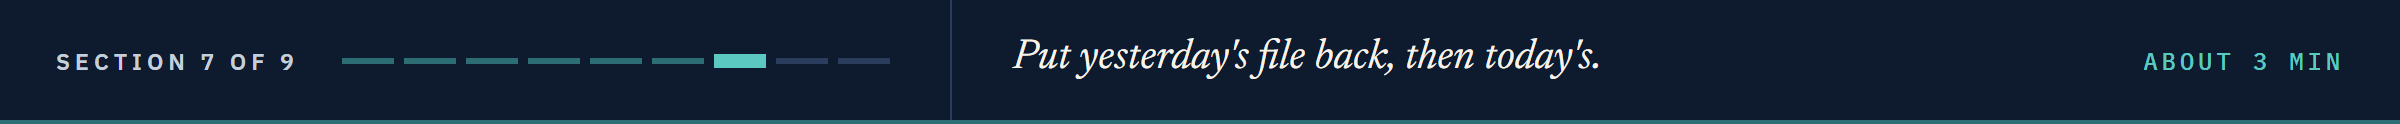

## 7.7 Yesterday's File, and Back: `git restore --source`

The module is done for the day.

### Read the Diff, Commit

In [33]:
# what changed, then the commit with the day's subject and the last three commits
!git -C "{work}" diff --stat
!git -C "{work}" add marketdata.py test_marketdata.py
!git -C "{work}" commit -q -m "Notebook 07: rolling_vol_bp and assert_no_lookahead"
!git -C "{work}" log --oneline -3

 marketdata.py      | 28 ++++++++++++++++++++++++++++
 test_marketdata.py | 48 ++++++++++++++++++++++++++++++++++++++++++++++++
 2 files changed, 76 insertions(+)
85a1fa6 Notebook 07: rolling_vol_bp and assert_no_lookahead
1f5838a Notebook 06: change_bp, return_pct, and change_since_bp
ace289a Notebook 05: write_cache, read_cache, and cached_fred_series


`HEAD~1` is the commit before `HEAD`, as Course 2's Duration and DV01 drew it in "Counting Back From HEAD".
`--source=HEAD~1` tells `git restore` to take the file as it was in that commit.

### Predict 5: What Moves Back?

**Predict 5**

Q. `git restore --source=HEAD~1 marketdata.py` puts notebook 06's `marketdata.py` in the folder. Then `git log --oneline -1` shows:

A) Notebook 06's commit: the history stepped back
B) today's commit, unchanged
C) a new commit holding the old file

### Yesterday's Version in the Folder

In [34]:
# notebook 06's file into the folder, then the status and the newest commit
!git -C "{work}" restore --source=HEAD~1 marketdata.py
!git -C "{work}" status --short
!git -C "{work}" log --oneline -1
# notebook 02's .read_text(): does the file hold today's function?
print('def rolling_vol_bp' in (work / 'marketdata.py').read_text())

 M marketdata.py
85a1fa6 Notebook 07: rolling_vol_bp and assert_no_lookahead
False


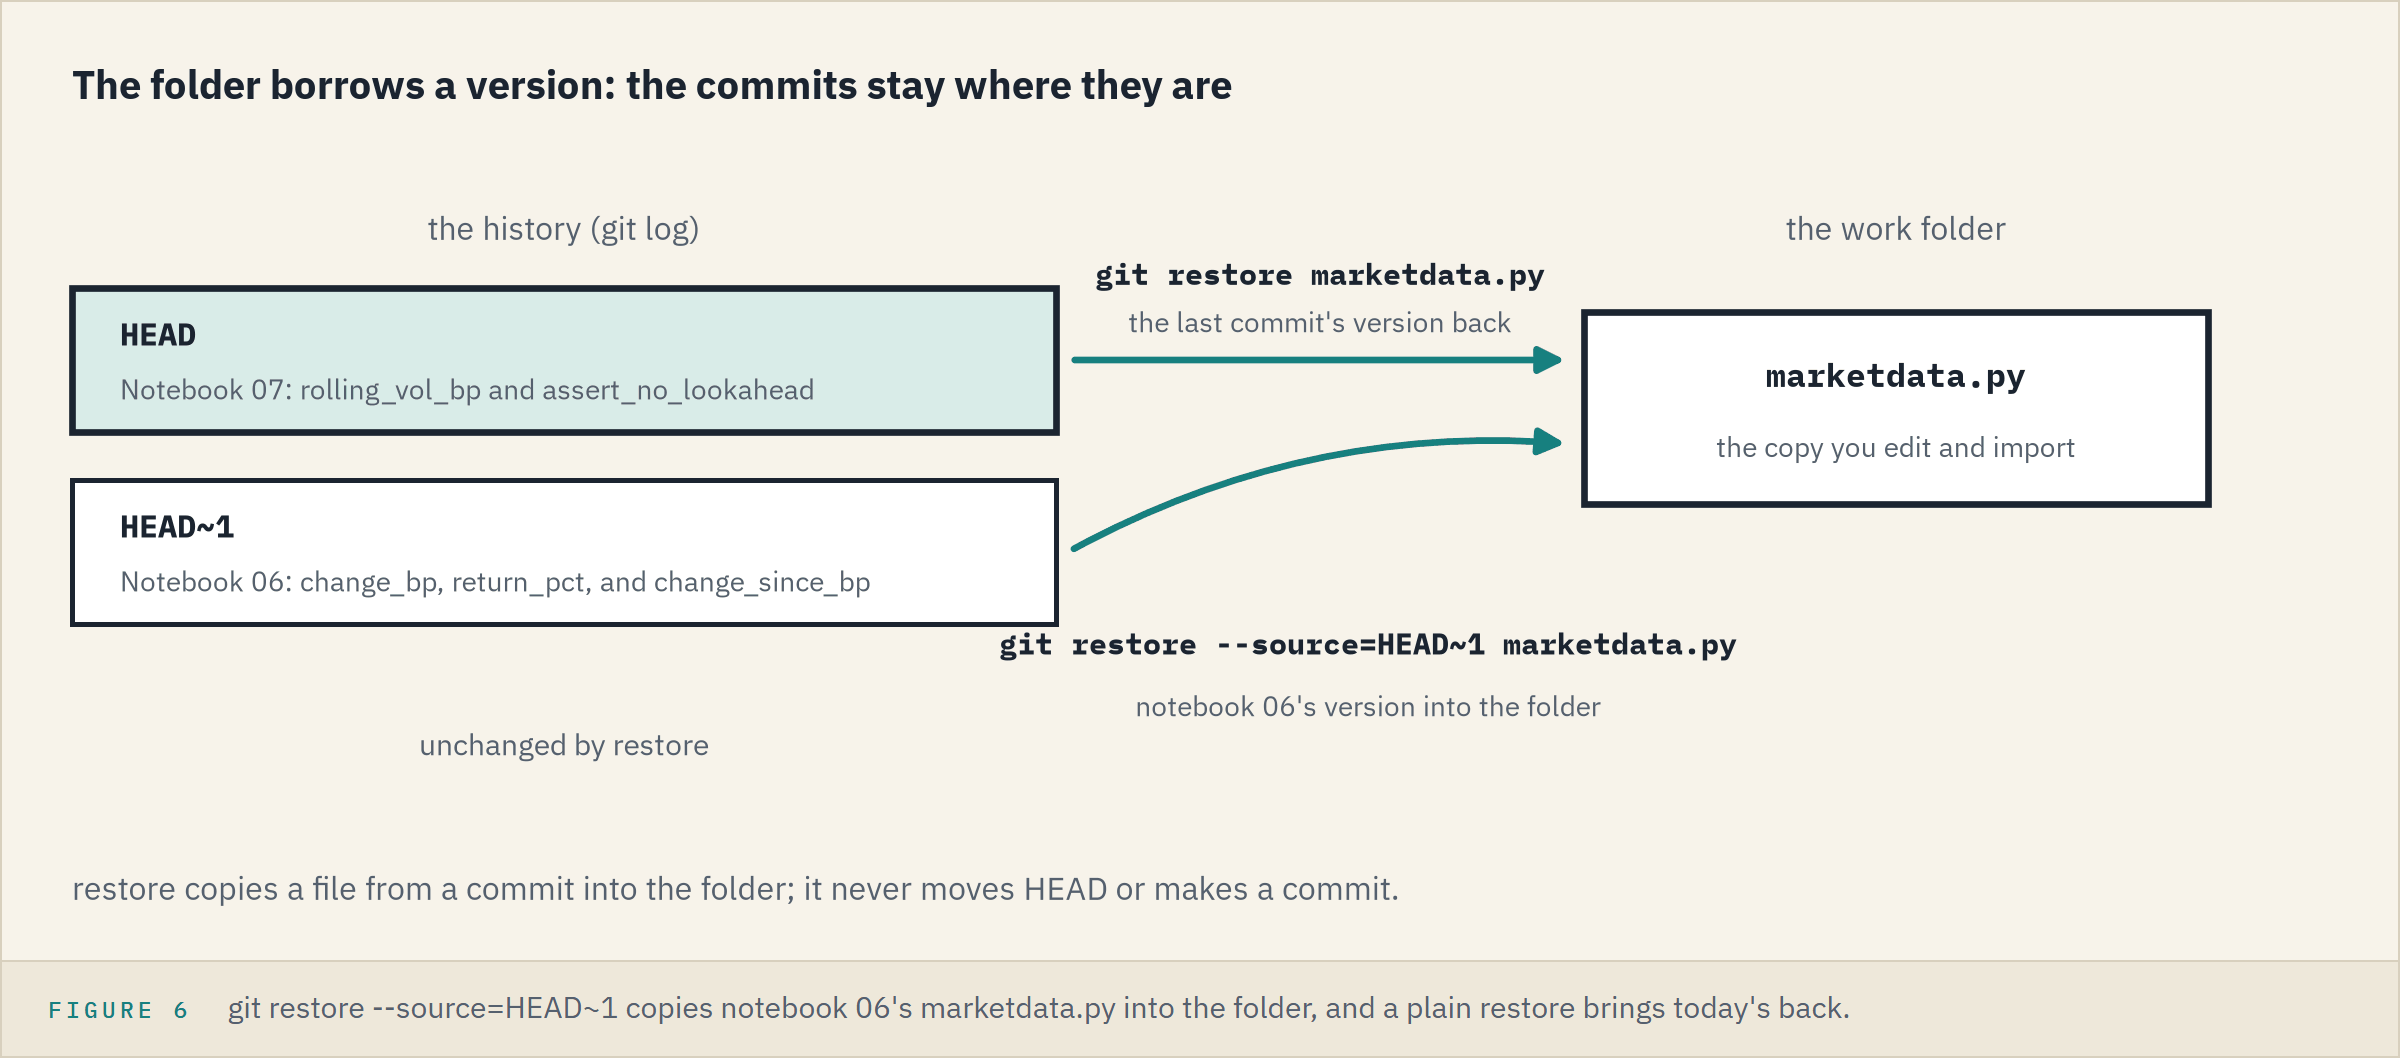

B: the folder holds yesterday's file and the history is untouched.
` M` marks it changed against today's commit.

### Back to Today's

In [35]:
# the last commit's file back, then the status and the same question
!git -C "{work}" restore marketdata.py
!git -C "{work}" status --short
print('def rolling_vol_bp' in (work / 'marketdata.py').read_text())

True


Plain `restore` throws away every change since the last commit, so read `status` first, as Course 2 warned.

**`--source=HEAD~1` puts yesterday's file in the folder without touching a commit, and plain `restore` brings today's back.**

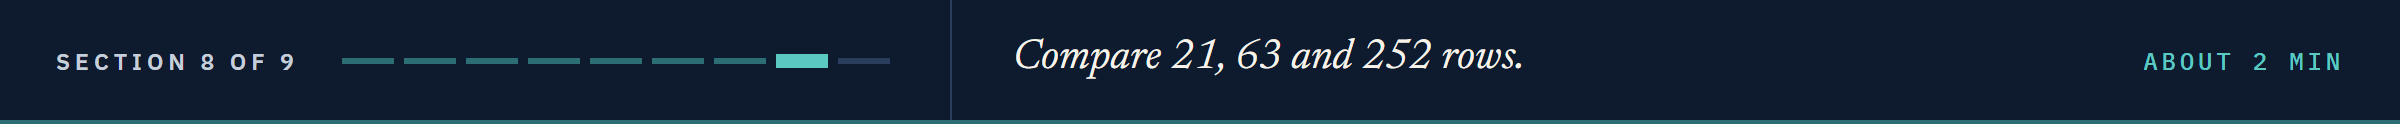

## 7.8 21, 63 and 252 Rows on One Chart

The note's last ask.

### Three Windows

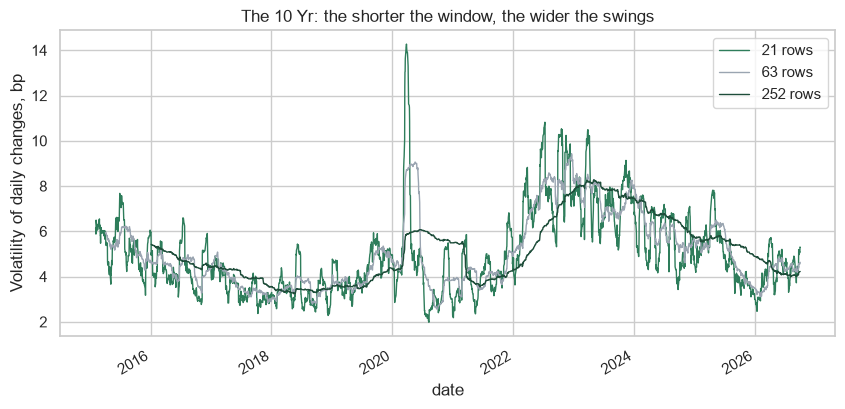

In [36]:
# about one, three and twelve months, in bp per day
vol63 = md.rolling_vol_bp(ten_changes, window=63)
vol252 = md.rolling_vol_bp(ten_changes, window=252)
vols = pd.DataFrame({'21 rows': vol21, '63 rows': vol63, '252 rows': vol252})
fig, ax = plt.subplots(figsize=(10, 4.5))
# linewidth=1: thin lines, so all three show
vols.plot(ax=ax, linewidth=1)
ax.set_title('The 10 Yr: the shorter the window, the wider the swings')
ax.set_ylabel('Volatility of daily changes, bp')
plt.show()

### As of 2 October

In [37]:
# each line's first value, its lowest and highest with their dates, and 2 October
for name in vols.columns:
    vol = vols[name].dropna()
    print(f'{name}: from {vol.index[0]:%Y-%m-%d}, low {vol.min():.2f} on {vol.idxmin():%Y-%m-%d}, '
          f'high {vol.max():.2f} on {vol.idxmax():%Y-%m-%d}, {vol.iloc[-1]:.2f} on 2026-10-02')

21 rows: from 2015-02-03, low 1.98 on 2020-08-10, high 14.27 on 2020-03-27, 5.29 on 2026-10-02
63 rows: from 2015-04-03, low 2.57 on 2020-09-29, high 9.43 on 2022-12-20, 4.63 on 2026-10-02
252 rows: from 2016-01-05, low 3.23 on 2018-05-21, high 8.26 on 2023-05-03, 4.22 on 2026-10-02


**Excel side by side.**

<table align="left">
<tr><th align="left">Job</th><th align="left">Python</th><th align="left">Excel</th><th align="left">Result</th></tr>
<tr><td align="left">63 rows, J65 filled down</td><td align="left"><code>md.rolling_vol_bp(ten_changes, window=63)</code></td><td align="left"><code>=STDEV.S(F3:F65)</code></td><td align="left">Within 1.1e-14 bp, the last 4.628823961301718</td></tr>
<tr><td align="left">252 rows, K254 filled down</td><td align="left"><code>md.rolling_vol_bp(ten_changes, window=252)</code></td><td align="left"><code>=STDEV.S(F3:F254)</code></td><td align="left">Within 1.1e-14 bp, the last 4.222979359434287</td></tr>
<tr><td align="left">The 21-row high</td><td align="left"><code>vol21.max()</code></td><td align="left"><code>=MAX(G23:G2941)</code></td><td align="left">14.27202</td></tr>
<tr><td align="left">Its date</td><td align="left"><code>vol21.idxmax()</code></td><td align="left"><code>=XLOOKUP(MAX(G23:G2941),G23:G2941,A23:A2941)</code></td><td align="left">43917, 2020-03-27 as a date</td></tr>
</table>
<br clear="left">

Course 1's Treasury Yields case study read 5.34 over 20 rows.
Today's 5.29 over 21 has a definition, an Excel tie and a no-lookahead test.
Each line says how much the 10 Yr moved over its own window, and none says what comes next.

**On 2 October 2026 the 10 Yr's daily changes had a volatility of 5.29 bp over 21 rows, 4.63 over 63 and 4.22 over 252. The note is answered.**

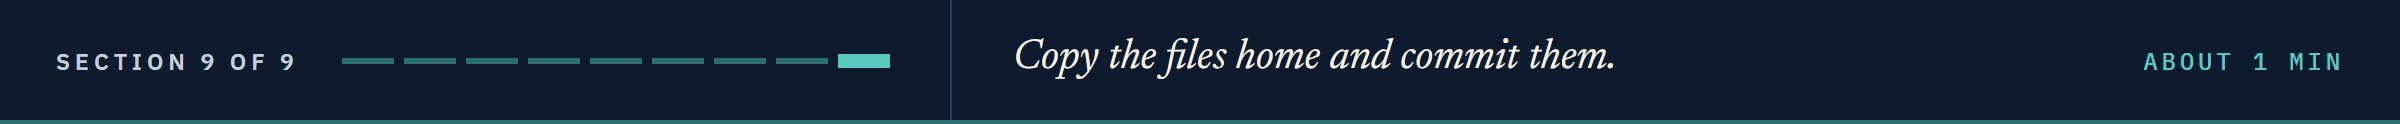

## Bring It Home

Copy the work folder's two files into your own `my_bondmath` folder, test them there, and commit.
The copy replaces your two files, so anything of your own must be in the work folder first.
The tests read the Treasury file and Excel's reference file, in your folder since notebooks 04 and 06.
In a PowerShell terminal in VS Code, with the course's `.venv` active:

```powershell
# the work folder: use the name your setup cell printed
$work = "$env:TEMP\pfi_course3_07_k4w7q2xr"
Set-Location "$HOME\projects\my_bondmath"
Copy-Item "$work\marketdata.py", "$work\test_marketdata.py" .
python -m pytest -q test_marketdata.py
git diff --stat
git add marketdata.py test_marketdata.py
git commit -m "Notebook 07: rolling_vol_bp and assert_no_lookahead"
git restore --source=HEAD~1 marketdata.py
git status --short
git restore marketdata.py
```

pytest shows 29 passed, and `status` shows ` M marketdata.py` until the last line brings today's file back.
In Colab, download the two files from the work folder under `/tmp` instead.
The work folder stays in your temp folder; the system clears it in time.

## You Can Now

By the end of this notebook, you can:

* Tell a window in rows from a window in calendar days, and say why the course counts rows.
* Keep to full windows with `min_periods`, as Excel leaves the cells above the first full range empty.
* Measure volatility with `rolling_vol_bp`, tied to Excel's `STDEV.S` filled down.
* Choose between the sample and population standard deviation, and name `ddof`.
* Annualise with the square root of 252, and label it.
* Prove a window function uses no future data with `assert_no_lookahead`.
* Put yesterday's file in the folder with `git restore --source=HEAD~1`, and bring today's back.

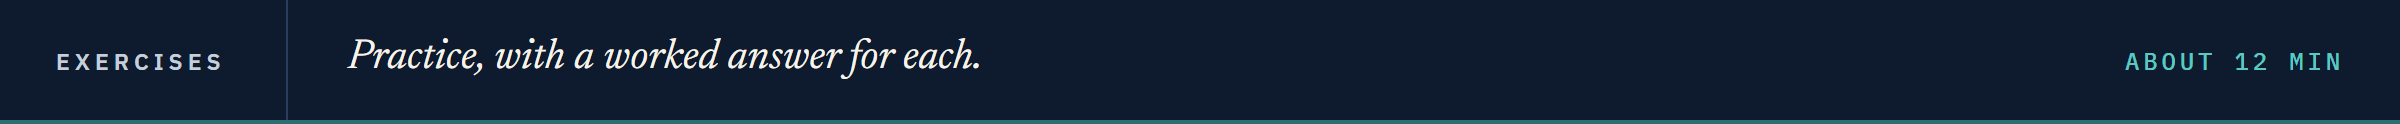

## Exercises

**Every exercise has a worked answer** in the solutions notebook in this folder: the one with this notebook's name ending in `_solutions.ipynb`.

Give each exercise a real try first, then check your work against it.

Every exercise uses `treasury`, `ten_changes` and `CUT_DATES` from above, and needs no key.
Replace each `...` with your code, then run the cell.
Run the next two cells first.

In [38]:
# check() compares your answer with the expected one and prints the result
def check(label, answer, expected):
    if answer is ...:
        print(label + ': not attempted yet')
        return
    if answer is None:
        print(label + ': not yet. Nothing came back: does your function end with return?')
        return
    # isinstance(x, list) is True when x is a list, so a list answer is compared value by value
    if isinstance(expected, list):
        correct = list(answer) == expected  # the same values in the same order
    # getattr(answer, 'ndim', 0) reads answer's ndim, its number of dimensions, as in NumPy
    # Part 1, and gives 0 when answer has none: a single number or a piece of text
    elif getattr(answer, 'ndim', 0) > 0:
        correct = False  # a column or a table where one value is expected
    elif isinstance(expected, float):
        # abs() drops the sign, so this is the size of the gap between the two decimals
        correct = abs(answer - expected) < 0.000001  # decimals: within a tiny tolerance
    else:
        correct = answer == expected
    print(label + ': correct' if correct else label + ': not yet. You have ' + str(answer))

In [39]:
# the synthetic spreads, in bp, invented for this course
spreads = pd.read_csv('course3_synthetic_spreads.csv', parse_dates=['date'], index_col='date',
                      float_precision='round_trip')

### Exercise 1

Q. Compute the 21-row volatility of the 5 Yr's daily changes and of the synthetic high yield spread's, `spreads['hy_spread_bp']`, already in bp, so `percent_units=False` (notebook 06). Store each one's value on 2026-10-02, in bp per day, in **ex1_five_year_bp** and **ex1_high_yield_bp**.

In [40]:
ex1_five_year_bp = ...
ex1_high_yield_bp = ...
check('Exercise 1 the 5 Yr', ex1_five_year_bp, 6.030083313015232)
check('Exercise 1 the high yield spread', ex1_high_yield_bp, 5.4347471137557255)

Exercise 1 the 5 Yr: not attempted yet
Exercise 1 the high yield spread: not attempted yet


### Exercise 2

Q. For each calendar year, on which date was the 63-row volatility of the 5 Yr's daily changes at its highest? Call the volatility `vol`, drop its `NaN`, take `.groupby(vol.index.year).idxmax()`, write the dates as text with `.dt.strftime('%Y-%m-%d')`, and store the result as a dictionary with `.to_dict()` in **ex2_dates**.

In [41]:
ex2_dates = ...
check('Exercise 2 the dates of the highest 63-row volatility', ex2_dates,
      {2015: '2015-04-06', 2016: '2016-08-12', 2017: '2017-02-09', 2018: '2018-06-14',
       2019: '2019-10-30', 2020: '2020-04-27', 2021: '2021-12-16', 2022: '2022-08-08',
       2023: '2023-06-02', 2024: '2024-01-02', 2025: '2025-05-12', 2026: '2026-05-26'})

Exercise 2 the dates of the highest 63-row volatility: not attempted yet


### Exercise 3

Q. Add `vol_ratio(short_vol, long_vol)` to your module, then test it and use it.

The function, docstring first: the short-window volatility over the long-window one, date by date, with no unit.

It raises `ValueError` when the two series do not have the same dates (`short_vol.index.equals(long_vol.index)` is `True` when they do).

`test_vol_ratio_hand_values` checks a `NaN`, two hand values and the error.

Run pytest, reload, and store the 5 Yr's 21-row over 252-row volatility on 2026-10-02 in **ex3_ratio**.

In [42]:
%%writefile -a marketdata.py


# Exercise 3: write vol_ratio(short_vol, long_vol) below this line

Appending to marketdata.py


In [43]:
%%writefile -a test_marketdata.py


# Exercise 3: write test_vol_ratio_hand_values() below this line

Appending to test_marketdata.py


In [44]:
# run pytest, reload the module, then store the answer
ex3_ratio = ...
check('Exercise 3 the volatility ratio', ex3_ratio, 1.2733566476405627)

Exercise 3 the volatility ratio: not attempted yet


### Exercise 4: AI check

You gave an AI assistant the docstring below as the request: the docstring is the prompt.
This came back, written for this course in the style of an assistant's answer.
`center=True` stores each window on its middle row instead of its last.

In [45]:
# written for this course in the style of an AI assistant's answer.
# It runs, and it contains one bug.
def trailing_vol_bp(changes_bp, window=63):
    """Volatility of daily changes in bp over a trailing window, for the desk's daily market table.

    Units: changes in bp in, bp per day out. Convention: the window ending on date t holds t
    and the window - 1 rows before it; full windows only; sample standard deviation (Excel
    STDEV.S). It uses no data after t: the value on any date is the same whether the series
    stops there or runs on.
    """
    # a window of `window` rows, full windows only, sample standard deviation
    return changes_bp.rolling(window, min_periods=window, center=True).std()

Q. Is its value on 2026-06-30 the same when the series stops there as when it runs on?

In [46]:
# the whole series, then the series cut at 2026-06-30
full = trailing_vol_bp(ten_changes)
stopped = trailing_vol_bp(ten_changes.loc[:'2026-06-30'])
print(f"2026-06-30: {full.loc['2026-06-30']:.4f} bp from the whole series, "
      f"{stopped.loc['2026-06-30']:.4f} cut there")

2026-06-30: 4.5551 bp from the whole series, nan cut there


Q. Run 7.6's check before you trust it.

In [47]:
# the no-lookahead check, written out at the three cut dates
full = trailing_vol_bp(ten_changes)
for cut in CUT_DATES:
    stopped = trailing_vol_bp(ten_changes.loc[:cut])
    assert full.loc[:cut].equals(stopped), f'values up to {cut} change when later rows arrive'
print('No lookahead on', CUT_DATES)

AssertionError: values up to 2025-04-17 change when later rows arrive

Q. Fix the function, run it and the test again, then store its value on 2026-10-02 in **ex4_last_bp**.

In [48]:
ex4_last_bp = ...
check('Exercise 4 the fixed function on the last date', ex4_last_bp, 4.628823961301708)

Exercise 4 the fixed function on the last date: not attempted yet


## Congratulations!

The note is answered:

<table align="left">
<tr><th align="left">The note asked</th><th align="left">Answer</th></tr>
<tr><td align="left">What 5.29 and 84.05 are</td><td align="left">One measure, the 21-row sample volatility of the 10 Yr's daily changes, per day and times the square root of 252</td></tr>
<tr><td align="left">One definition in <code>marketdata</code></td><td align="left"><code>rolling_vol_bp</code>, in rows, trailing, full windows, <code>ddof=1</code>, per day unless annual</td></tr>
<tr><td align="left">Tied to Excel</td><td align="left"><code>STDEV.S</code> filled down, 190 of 190 rows of 2026, 29 passed</td></tr>
<tr><td align="left">No future row</td><td align="left"><code>assert_no_lookahead</code> on three cut dates</td></tr>
<tr><td align="left">One, three and twelve months</td><td align="left">5.29, 4.63 and 4.22 bp a day as of 2026-10-02</td></tr>
</table>
<br clear="left">

Be proud: few desk spreadsheets were ever asked whether a number saw the future, and yours now answers that in one line.

Next, Z-Scores and Percentile Ranks (notebook 08) uses the same windows to say where today sits in its own history.

[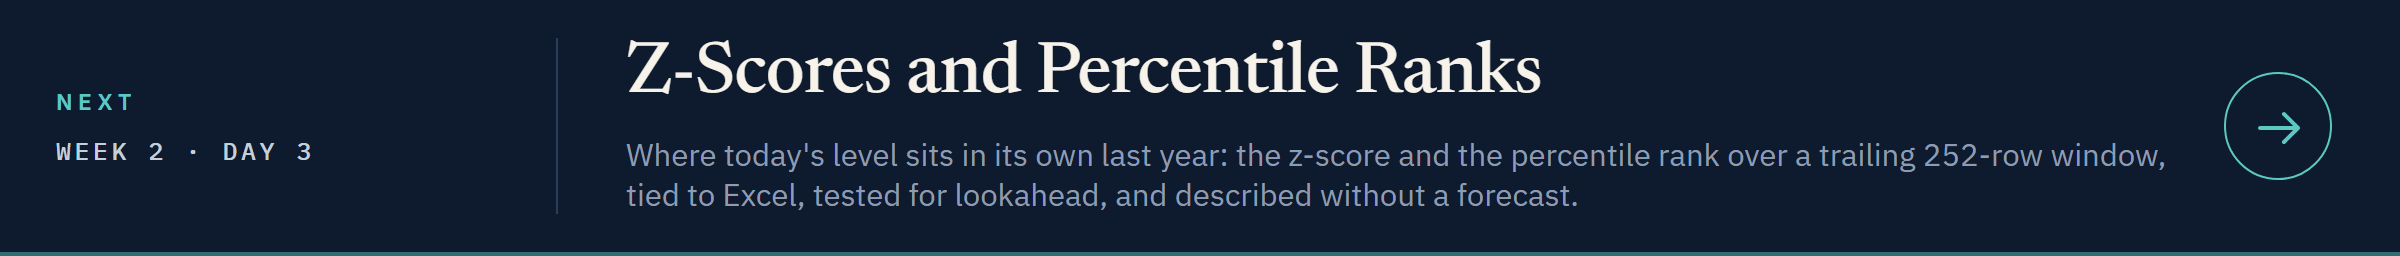](../day3/08_z_scores_and_percentile_ranks.ipynb)

[Open Day 3 in Colab](https://colab.research.google.com/github/lenamonj/python-fixed-income/blob/main/course03_market_data/week2/day3/08_z_scores_and_percentile_ranks.ipynb)